# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization

**Academic Year:** 2025/2026

### Team Members :
1. Al-Jnainati, Mohammad  (S360905)
2. Hmedeh , Abdallah (S360907)

In [1]:
StudentIDs = [360905,360907]  # <-------- Fill this list with Student IDs of the team

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Branded clothing
Spending on looks
Spending on healthy eating
Smoking
Alcohol
Healthy eating
History
Psychology
Politics
Physics
Internet
Economy Management
Biology
Chemistry
Reading
Geography
Cars
Countryside, outdoors
Musical instruments
Writing
Passive sport
Active sport
Gardening
Shopping
Science and technology
Adrenaline sports
Movies
Horror
Romantic
Sci-fi
War
Fantasy/Fairy tales
Documentary
Western
Music
Slow songs or fast songs
Classical music
Musical
Pop
Metal or Hardrock
Hiphop, Rap
Reggae, Ska
Swing, Jazz
Rock n roll
Latino
Techno, Trance
Daily events
Prioritising workload
Writing notes
Workaholism
Thinking ahead
Final judgement
Keeping promises
Funniness
Fake
Criminal damage
Elections
Self-criticism
Judgment calls
Empathy
Giving
Compassion to animals
Loneliness
Cheating in school
God
Dreams
Charity
Number of friends
Punctuality
Lying
Mood swings
Appearence and gestures
Achievements
Responding to a seri

,Finances,Branded clothing,Spending on looks,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Psychology,Politics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
16,2,3,2,4,never smoked,never,2,5,3,4,...,20,186,77,1,male,right,secondary school,no,city,block of flats
668,3,3,3,4,former smoker,social drinker,3,3,4,3,...,20,172,63,1,female,right,secondary school,no,city,house/bungalow
76,4,1,4,3,tried smoking,drink a lot,3,3,1,2,...,21,172,71,1,female,right,secondary school,no,city,block of flats
217,4,4,3,4,never smoked,social drinker,1,5,5,2,...,20,190,92,1,male,right,college/bachelor degree,no,city,house/bungalow
628,3,2,3,4,former smoker,social drinker,4,3,2,2,...,18,165,45,5,female,left,primary school,no,city,block of flats
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,4,1,4,4,never smoked,drink a lot,3,5,2,4,...,25,177,97,1,male,left,doctorate degree,yes,city,block of flats
135,4,2,1,3,never smoked,social drinker,3,4,3,2,...,17,166,54,1,female,right,primary school,no,city,block of flats
459,3,2,4,4,tried smoking,social drinker,2,1,2,4,...,18,173,67,1,male,right,college/bachelor degree,no,city,block of flats
365,1,2,3,5,tried smoking,drink a lot,3,4,2,2,...,19,185,74,1,male,right,primary school,no,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Branded clothing,Spending on looks,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Psychology,Politics,...,Parents' advice,Internet usage,Flying,Heights,Spiders,Snakes,Rats,Ageing,Dangerous dogs,Fear of public speaking
16,2,3,2,4,never smoked,never,2,5,3,4,...,3,few hours a day,2,2,2,2,2,1,1,2
668,3,3,3,4,former smoker,social drinker,3,3,4,3,...,4,few hours a day,4,4,4,5,4,1,3,2
76,4,1,4,3,tried smoking,drink a lot,3,3,1,2,...,4,few hours a day,3,5,4,3,3,1,5,3
217,4,4,3,4,never smoked,social drinker,1,5,5,2,...,4,few hours a day,2,2,1,1,1,1,2,3
628,3,2,3,4,former smoker,social drinker,4,3,2,2,...,3,few hours a day,3,4,5,5,5,3,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,4,1,4,4,never smoked,drink a lot,3,5,2,4,...,3,few hours a day,1,5,1,1,1,1,5,2
135,4,2,1,3,never smoked,social drinker,3,4,3,2,...,3,few hours a day,1,2,3,3,2,2,2,5
459,3,2,4,4,tried smoking,social drinker,2,1,2,4,...,4,less than an hour a day,1,2,1,3,3,3,2,3
365,1,2,3,5,tried smoking,drink a lot,3,4,2,2,...,3,few hours a day,1,2,1,3,1,5,2,4



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
16,20,186,77,1,male,right,secondary school,no,city,block of flats
668,20,172,63,1,female,right,secondary school,no,city,house/bungalow
76,21,172,71,1,female,right,secondary school,no,city,block of flats
217,20,190,92,1,male,right,college/bachelor degree,no,city,house/bungalow
628,18,165,45,5,female,left,primary school,no,city,block of flats
...,...,...,...,...,...,...,...,...,...,...
115,25,177,97,1,male,left,doctorate degree,yes,city,block of flats
135,17,166,54,1,female,right,primary school,no,city,block of flats
459,18,173,67,1,male,right,college/bachelor degree,no,city,block of flats
365,19,185,74,1,male,right,primary school,no,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec



## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE MinMaxScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
**The dataset contains a limited number of categorical features namely :**  
**-Smoking**  
**-Alcohol**  
**-Punctuality**  
**-Lying**  
**-Internet Usage**


  
These variables were first inspected by analyzing their unique values in order to identify the admissible categories. Since all these features exhibit a natural ordering (e.g., increasing smoking or alcohol consumption, punctuality behavior, and frequency of lying), an ordinal encoding strategy was adopted. Each category was mapped to an integer reflecting its semantic order, preserving the relative meaning among categories. This approach allows categorical information to be converted into numerical form while maintaining interpretability and ensuring compatibility with subsequent numerical methods such as PCA.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
After encoding all categorical features, the dataset was preprocessed using MinMax scaling, as required by the assignment. MinMaxScaler rescales each feature independently to the interval \([0,1]\) according to the formula:

$$
x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

where *Xmin* and *Xmax* denote the minimum and maximum values of the feature, respectively. This preprocessing step is necessary because PCA is sensitive to the scale of the variables, and features originally measured on different ranges could otherwise dominate the variance structure. MinMax scaling ensures that all features contribute equally to the analysis while preserving their relative ordering and proportional differences.


#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [5]:
# Make a copy of the feature dataset
responses_ft_enc = responses_ft.copy()
#Specifying the non-numerical features 
print("THE NON - NUMERICAL FEATURES ARE:")
a=responses_ft.select_dtypes(exclude=['number']).columns
print(a)
#Checking the unique values in each non-numerical feature
print("\nChecking the unique values in each non-numerical feature")
print("\nFOR SMOKING: ",responses_ft_enc['Smoking'].unique())
print("\nFOR ALCOHOL: ",responses_ft_enc['Alcohol'].unique())
print("\nFOR PUNCTUALITY: ",responses_ft_enc['Punctuality'].unique())
print("\nFOR LYING: ",responses_ft_enc['Lying'].unique())
print("\nFOR INTERNET USAGE: ",responses_ft_enc['Internet usage'].unique())

THE NON - NUMERICAL FEATURES ARE:
Index(['Smoking', 'Alcohol', 'Punctuality', 'Lying', 'Internet usage'], dtype='object')

Checking the unique values in each non-numerical feature

FOR SMOKING:  ['never smoked' 'former smoker' 'tried smoking' 'current smoker']

FOR ALCOHOL:  ['never' 'social drinker' 'drink a lot']

FOR PUNCTUALITY:  ['early' 'on time' 'late']

FOR LYING:  ['only to avoid hurting someone' 'sometimes' 'never'
 'everytime it suits me']

FOR INTERNET USAGE:  ['few hours a day' 'most of the day' 'less than an hour a day']


In [6]:
smoking_map = {
    'never smoked': 0,
    'tried smoking': 1,
    'former smoker': 2,
    'current smoker': 3
}

alcohol_map = {
    'never': 0,
    'social drinker': 1,
    'drink a lot': 2
}

punctuality_map = {
    'early': 2,
    'on time': 1,
    'late': 0
}

lying_map = {
    'never': 0,
    'only to avoid hurting someone': 1,
    'sometimes': 2,
    'everytime it suits me': 3
}
internet_map = {
    'no time at all': 0,
    'less than an hour a day': 1,
    'few hours a day': 2,
    'most of the day': 3
}
#Apply the encoding maps to the respective columns
responses_ft_enc['Smoking'] = responses_ft_enc['Smoking'].map(smoking_map)
responses_ft_enc['Alcohol'] = responses_ft_enc['Alcohol'].map(alcohol_map)
responses_ft_enc['Punctuality'] = responses_ft_enc['Punctuality'].map(punctuality_map)
responses_ft_enc['Lying'] = responses_ft_enc['Lying'].map(lying_map)
responses_ft_enc['Internet usage'] = responses_ft_enc['Internet usage'].map(internet_map)
# Check that there are no non-numerical columns left
responses_ft_enc.select_dtypes(exclude=['number']).columns
display(responses_ft_enc)

,Finances,Branded clothing,Spending on looks,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Psychology,Politics,...,Parents' advice,Internet usage,Flying,Heights,Spiders,Snakes,Rats,Ageing,Dangerous dogs,Fear of public speaking
16,2,3,2,4,0,0,2,5,3,4,...,3,2,2,2,2,2,2,1,1,2
668,3,3,3,4,2,1,3,3,4,3,...,4,2,4,4,4,5,4,1,3,2
76,4,1,4,3,1,2,3,3,1,2,...,4,2,3,5,4,3,3,1,5,3
217,4,4,3,4,0,1,1,5,5,2,...,4,2,2,2,1,1,1,1,2,3
628,3,2,3,4,2,1,4,3,2,2,...,3,2,3,4,5,5,5,3,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,4,1,4,4,0,2,3,5,2,4,...,3,2,1,5,1,1,1,1,5,2
135,4,2,1,3,0,1,3,4,3,2,...,3,2,1,2,3,3,2,2,2,5
459,3,2,4,4,1,1,2,1,2,4,...,4,1,1,2,1,3,3,3,2,3
365,1,2,3,5,1,2,3,4,2,2,...,3,2,1,2,1,3,1,5,2,4


In [7]:
cols = ['Smoking', 'Alcohol', 'Punctuality', 'Lying' , 'Internet usage']
comparison = pd.concat(
    [responses_ft[cols], responses_ft_enc[cols]],
    axis=1,
    keys=['Before encoding', 'After encoding']
)
display(comparison.head(10))

Before encoding                              \
            Smoking         Alcohol Punctuality   
16     never smoked           never       early   
668   former smoker  social drinker     on time   
76    tried smoking     drink a lot     on time   
217    never smoked  social drinker        late   
628   former smoker  social drinker     on time   
374   former smoker  social drinker        late   
577   tried smoking     drink a lot        late   
277    never smoked  social drinker     on time   
619   tried smoking  social drinker       early   
550  current smoker  social drinker        late   

                                                    After encoding          \
                             Lying   Internet usage        Smoking Alcohol   
16   only to avoid hurting someone  few hours a day              0       0   
668                      sometimes  few hours a day              2       1   
76   only to avoid hurting someone  few hours a day              1       2   
217  only to avoid hurting someone  few hours a day              0       1   
628  only to avoid hurting someone  few hours a day              2       1   
374                      sometimes  few hours a day              2       1   
577                      sometimes  few hours a day              1       2   
277                      sometimes  few hours a day              0       1   
619                      sometimes  few hours a day              1       1   
550                      sometimes  few hours a day              3       1   

                                      
    Punctuality Lying Internet usage  
16            2     1              2  
668           1     2              2  
76            1     1              2  
217           0     1              2  
628           1     1              2  
374           0     2              2  
577           0     2              2  
277           1     2              2  
619           2     2              2  
550           0     2              2

In [8]:
# """""NOW PREPROCESSING THE DATA"""""

# 1) Create the scaler 
scaler = MinMaxScaler()
# 2) Fit + transform the encoded data (scales each column to [0, 1])
X_scaled = scaler.fit_transform(responses_ft_enc)
# 3) Convert back to DataFrame (keep same columns + index)
responses_ft_pp = pd.DataFrame(
    X_scaled,
    columns=responses_ft_enc.columns,
    index=responses_ft_enc.index
)
print("THIS IS THE PREPROCESSED DATASET: ")
display(responses_ft_pp)
responses_ft_pp.describe().loc[['min', 'max']]

print("NOW LET US CHECK THE UNKOWN VALUES AFTER PREPROCESSING: ")
print(responses_ft.select_dtypes(exclude=['number']).isin(
    ['unknown', 'Unknown', 'UNKNOWN', 'other', 'Other', '']
).sum())
responses_ft_pp.select_dtypes(include=['number']).isin(
    ['unknown', 'Unknown', 'UNKNOWN', 'other', 'Other', '']
).sum()

THIS IS THE PREPROCESSED DATASET: 

,Finances,Branded clothing,Spending on looks,Spending on healthy eating,Smoking,Alcohol,Healthy eating,History,Psychology,Politics,...,Parents' advice,Internet usage,Flying,Heights,Spiders,Snakes,Rats,Ageing,Dangerous dogs,Fear of public speaking
16,0.25,0.50,0.25,0.75,0.000000,0.0,0.25,1.00,0.50,0.75,...,0.50,0.5,0.25,0.25,0.25,0.25,0.25,0.00,0.00,0.25
668,0.50,0.50,0.50,0.75,0.666667,0.5,0.50,0.50,0.75,0.50,...,0.75,0.5,0.75,0.75,0.75,1.00,0.75,0.00,0.50,0.25
76,0.75,0.00,0.75,0.50,0.333333,1.0,0.50,0.50,0.00,0.25,...,0.75,0.5,0.50,1.00,0.75,0.50,0.50,0.00,1.00,0.50
217,0.75,0.75,0.50,0.75,0.000000,0.5,0.00,1.00,1.00,0.25,...,0.75,0.5,0.25,0.25,0.00,0.00,0.00,0.00,0.25,0.50
628,0.50,0.25,0.50,0.75,0.666667,0.5,0.75,0.50,0.25,0.25,...,0.50,0.5,0.50,0.75,1.00,1.00,1.00,0.50,1.00,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0.75,0.00,0.75,0.75,0.000000,1.0,0.50,1.00,0.25,0.75,...,0.50,0.5,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.25
135,0.75,0.25,0.00,0.50,0.000000,0.5,0.50,0.75,0.50,0.25,...,0.50,0.5,0.00,0.25,0.50,0.50,0.25,0.25,0.25,1.00
459,0.50,0.25,0.75,0.75,0.333333,0.5,0.25,0.00,0.25,0.75,...,0.75,0.0,0.00,0.25,0.00,0.50,0.50,0.50,0.25,0.50
365,0.00,0.25,0.50,1.00,0.333333,1.0,0.50,0.75,0.25,0.25,...,0.50,0.5,0.00,0.25,0.00,0.50,0.00,1.00,0.25,0.75


NOW LET US CHECK THE UNKOWN VALUES AFTER PREPROCESSING: 
Smoking           0
Alcohol           0
Punctuality       0
Lying             0
Internet usage    0
dtype: int64


Finances                      0
Branded clothing              0
Spending on looks             0
Spending on healthy eating    0
Smoking                       0
                             ..
Snakes                        0
Rats                          0
Ageing                        0
Dangerous dogs                0
Fear of public speaking       0
Length: 93, dtype: int64

#### Comment the results obtained after the preprocessing operation (max 100 words):
After preprocessing, all features are successfully transformed into numerical values and scaled to the interval [0,1]. This confirms that the encoding and MinMax scaling steps were correctly applied. The scaling ensures that all variables are on a comparable scale, preventing features with larger original ranges from dominating the analysis. The relative ordering of observations within each feature is preserved, while improving numerical stability for subsequent methods such as PCA. No missing or unknown values were introduced during preprocessing, indicating that the transformed dataset is consistent and suitable for further analysis.

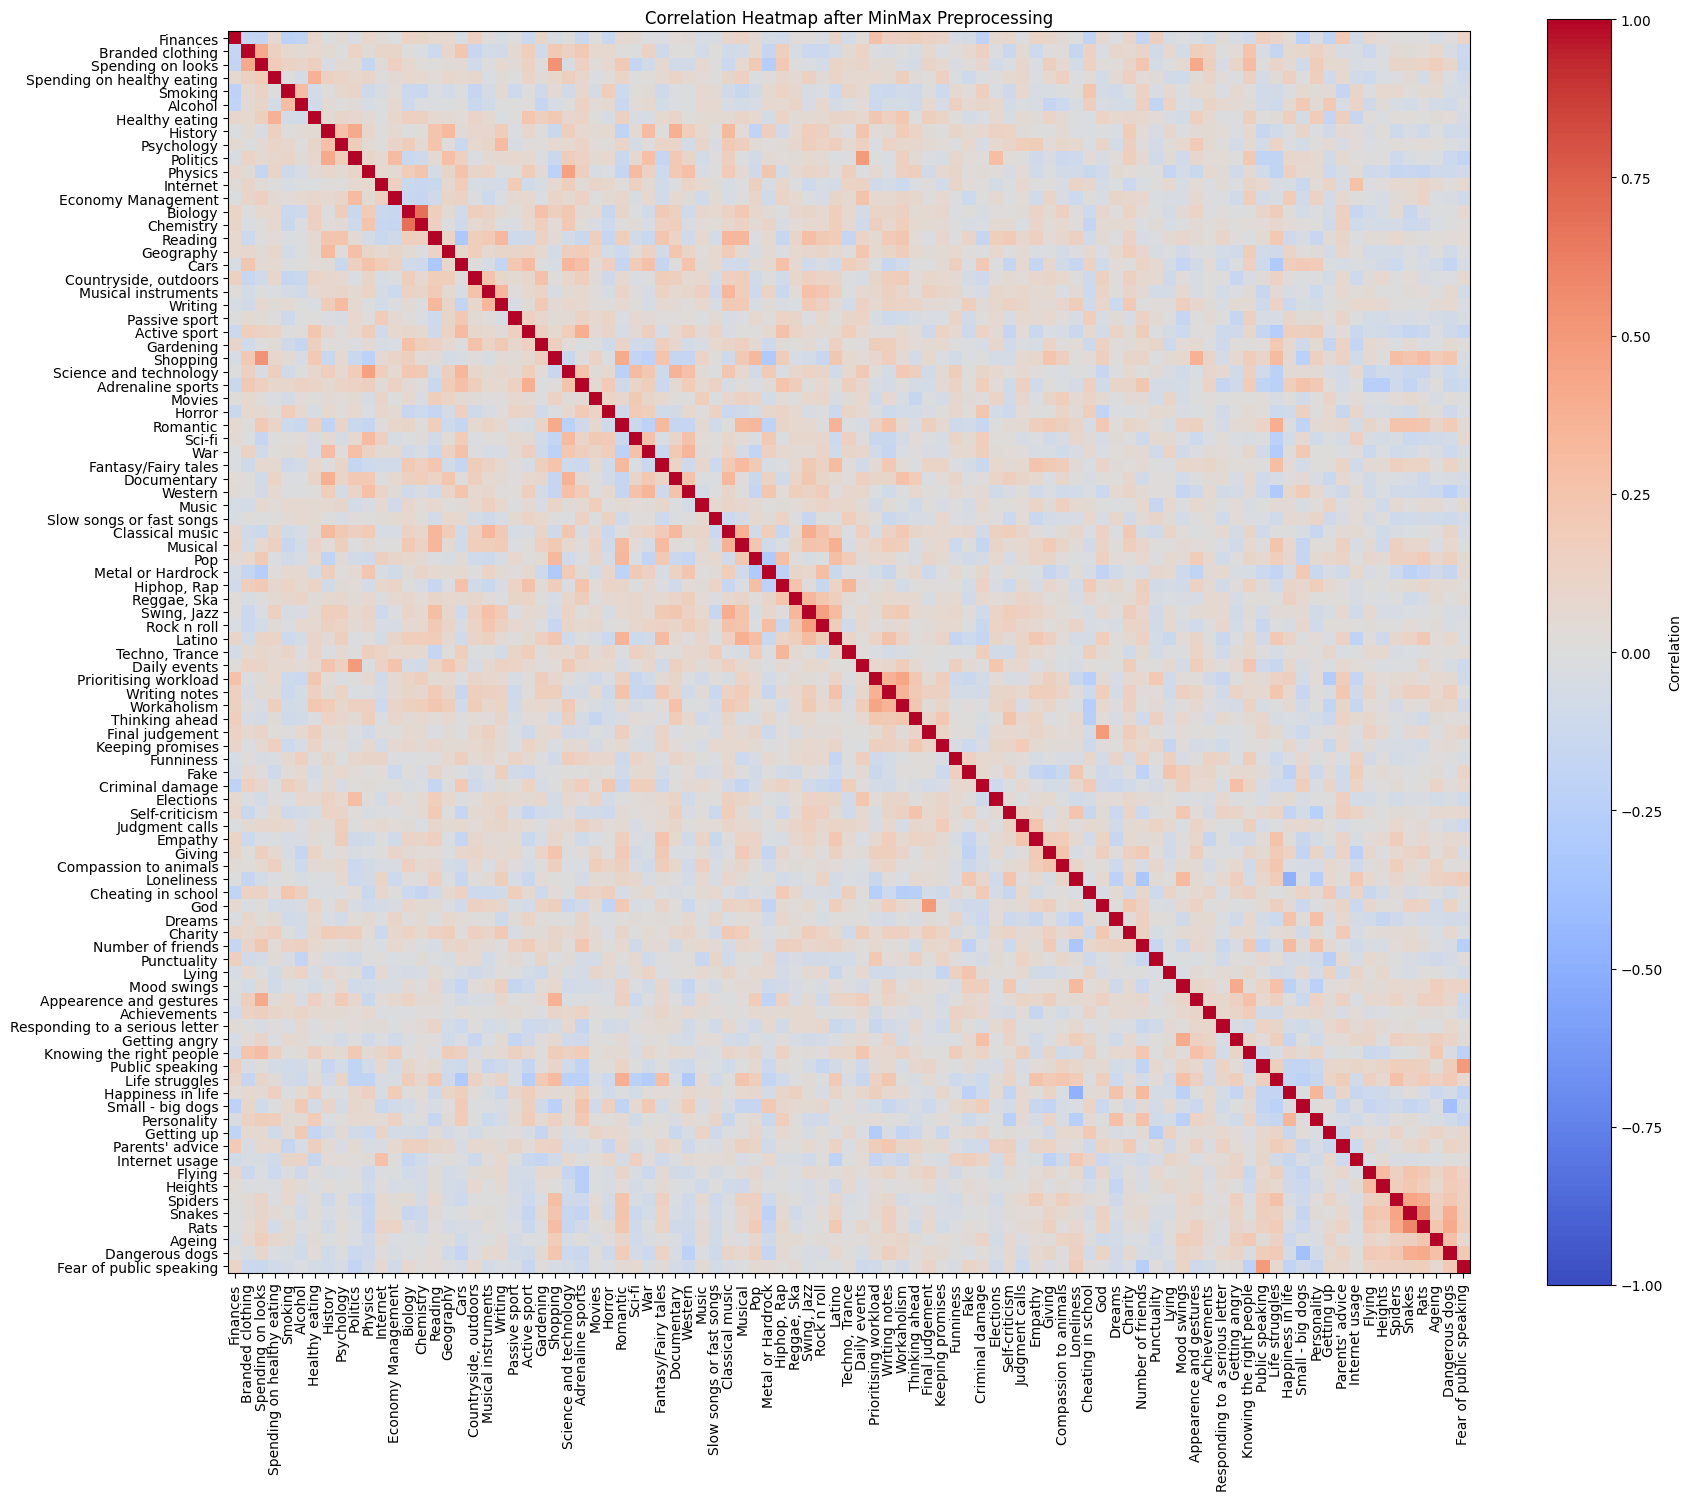

In [9]:
# Compute correlation matrix
corr = responses_ft_pp.corr()
# Create the heatmap
plt.figure(figsize=(18, 15))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

# Axis ticks and labels
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap after MinMax Preprocessing")
plt.tight_layout()
plt.show()

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

Variance of encoded data:


Finances                      1.308250
Branded clothing              1.784155
Spending on looks             1.517415
Spending on healthy eating    1.144883
Smoking                       0.945361
                                ...   
Snakes                        2.264474
Rats                          1.919164
Ageing                        1.867851
Dangerous dogs                1.920776
Fear of public speaking       1.409968
Length: 93, dtype: float64

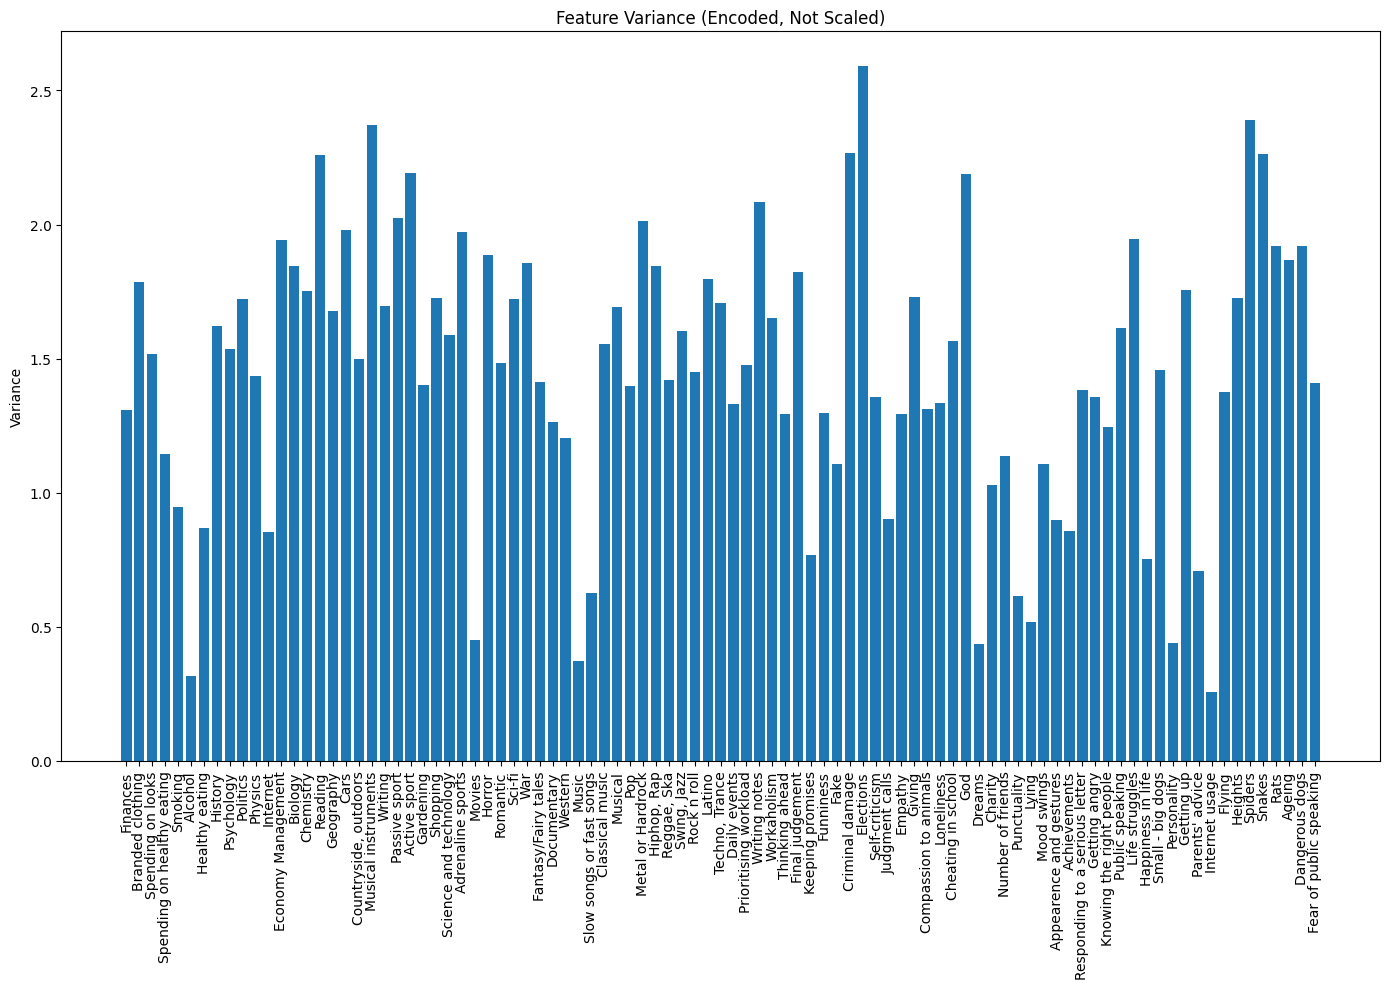

In [10]:
# [write the code here]
variance_enc = responses_ft_enc.var()
variance_pp = responses_ft_pp.var()
print("Variance of encoded data:")
display(variance_enc)
plt.figure(figsize=(14, 10))
plt.bar(variance_enc.index, variance_enc.values)
plt.xticks(rotation=90)
plt.title("Feature Variance (Encoded, Not Scaled)")
plt.ylabel("Variance")
plt.tight_layout()
plt.show()


**Feature Variance After MinMax Scaling**

Variance of preprocessed data:


Finances                      0.081766
Branded clothing              0.111510
Spending on looks             0.094838
Spending on healthy eating    0.071555
Smoking                       0.105040
                                ...   
Snakes                        0.141530
Rats                          0.119948
Ageing                        0.116741
Dangerous dogs                0.120049
Fear of public speaking       0.088123
Length: 93, dtype: float64

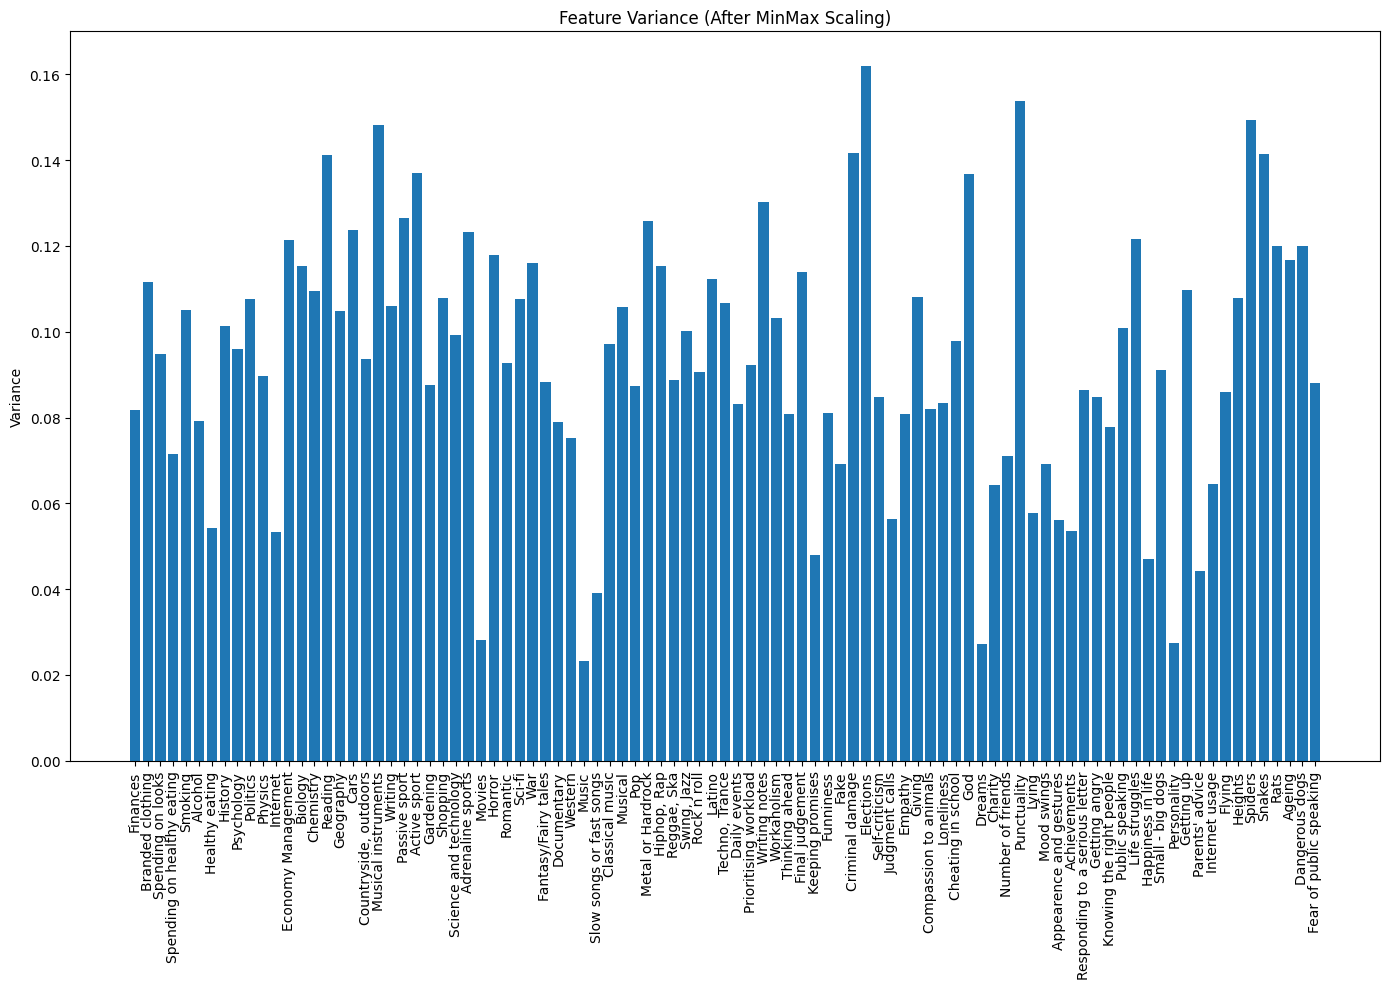

In [11]:
print("Variance of preprocessed data:")
display(variance_pp)
plt.figure(figsize=(14, 10))
plt.bar(variance_pp.index, variance_pp.values)
plt.xticks(rotation=90)
plt.title("Feature Variance (After MinMax Scaling)")
plt.ylabel("Variance")
plt.tight_layout()
plt.show()


### TOP 10 FEATURES BEFORE AND AFTER SCALING 

Text(0, 0.5, 'Variance')

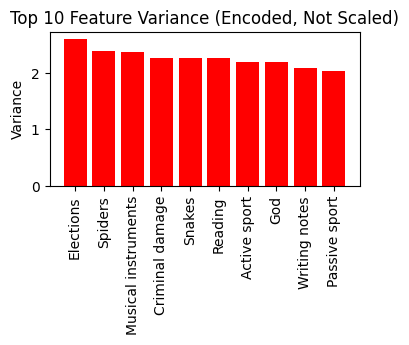

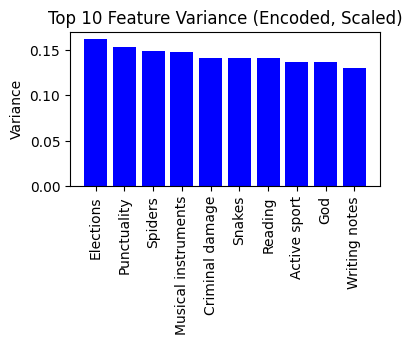

In [12]:
top10_variance_enc = variance_enc.sort_values(ascending=False).head(10)
plt.figure(figsize=(4,2))
plt.bar(top10_variance_enc.index, top10_variance_enc.values, color='red')
plt.xticks(rotation=90)
plt.title("Top 10 Feature Variance (Encoded, Not Scaled)")
plt.ylabel("Variance")  
top10_variance_pp = variance_pp.sort_values(ascending=False).head(10)
plt.figure(figsize=(4,2))
plt.bar(top10_variance_pp.index, top10_variance_pp.values, color='blue')
plt.xticks(rotation=90)
plt.title("Top 10 Feature Variance (Encoded, Scaled)")
plt.ylabel("Variance")  



The comparison of the top-variance features before and after MinMax scaling highlights how preprocessing mitigates scale-driven dominance and ensures a more balanced contribution of all features

#### Comment the results obtained for the variances (max 150 words):
The variance analysis highlights which features exhibit the greatest variability across respondents. Before preprocessing, features measured on larger or less constrained scales tended to show higher variance, potentially dominating subsequent analyses. After applying MinMax scaling, all features were rescaled to the common [0,1] interval, making their variances directly comparable. The post-scaling results show that differences in variance now reflect genuine variability in responses rather than differences in measurement scales. Features such as Elections, Punctuality, and Active sport remain among the most variable, indicating heterogeneous opinions or behaviors among participants. This confirms the necessity of preprocessing before applying PCA, as scaling prevents features with originally larger ranges from disproportionately influencing the variance structure and ensures a balanced contribution of all variables

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

,PC,ExplainedVarianceRatio,CumulativeExplainedVariance
0,1,0.078577,0.078577
1,2,0.062737,0.141314
2,3,0.051820,0.193134
3,4,0.036846,0.229980
4,5,0.031912,0.261892
5,6,0.029565,0.291457
6,7,0.026954,0.318411
7,8,0.023883,0.342294
8,9,0.023335,0.365628
9,10,0.020777,0.386405


,PC,ExplainedVarianceRatio,CumulativeExplainedVariance
0,1,0.076438,0.076438
1,2,0.060884,0.137322
2,3,0.050497,0.187819
3,4,0.037598,0.225417
4,5,0.031196,0.256614
5,6,0.029906,0.286520
6,7,0.026254,0.312774
7,8,0.023228,0.336002
8,9,0.022724,0.358726
9,10,0.022028,0.380754


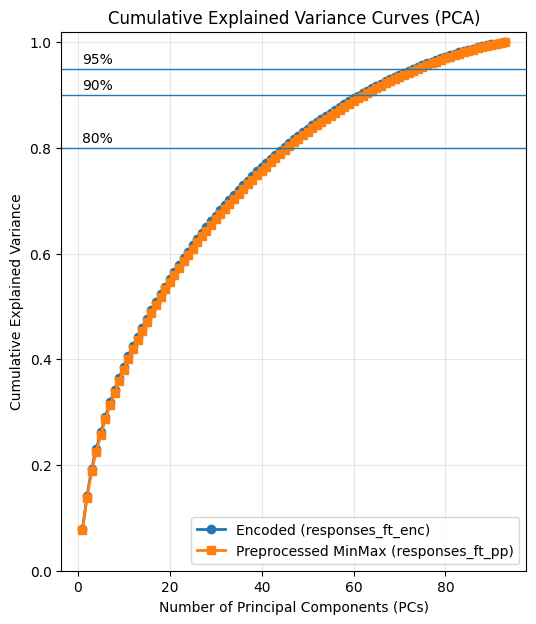

Number of PCs needed to reach each threshold:

80% variance:
 - responses_ft_enc: 45 PCs
 - responses_ft_pp : 46 PCs

90% variance:
 - responses_ft_enc: 62 PCs
 - responses_ft_pp : 63 PCs

95% variance:
 - responses_ft_enc: 73 PCs
 - responses_ft_pp : 75 PCs



In [13]:
# -----------------------------
# Helper function: PCA + cumulative explained variance
# -----------------------------
def run_pca_and_get_cumvar(df, dataset_name="dataset"):
    """
    Runs PCA with n_components = number of columns (all PCs),
    returns explained variance ratio and cumulative explained variance.
    """
    # PCA expects no missing values
    if df.isnull().any().any():
        raise ValueError(f"{dataset_name} contains NaN values. Handle missing values before PCA.")

    n_features = df.shape[1]  # number of original features = number of PCs
    pca = PCA(n_components=n_features, random_state=42)
    pca.fit(df)

    explained_var_ratio = pca.explained_variance_ratio_
    cum_explained_var = np.cumsum(explained_var_ratio)

    return pca, explained_var_ratio, cum_explained_var


# -----------------------------
# 1) Run PCA on both datasets
# -----------------------------
pca_enc, evr_enc, cumvar_enc = run_pca_and_get_cumvar(responses_ft_enc, "responses_ft_enc")
pca_pp,  evr_pp,  cumvar_pp  = run_pca_and_get_cumvar(responses_ft_pp,  "responses_ft_pp")


# -----------------------------
# 2) Put results in DataFrames (optional but useful for reporting)
# -----------------------------
pcs = np.arange(1, responses_ft_enc.shape[1] + 1)

pca_results_enc = pd.DataFrame({
    "PC": pcs,
    "ExplainedVarianceRatio": evr_enc,
    "CumulativeExplainedVariance": cumvar_enc
})

pca_results_pp = pd.DataFrame({
    "PC": pcs,
    "ExplainedVarianceRatio": evr_pp,
    "CumulativeExplainedVariance": cumvar_pp
})

display(pca_results_enc.head(10))
display(pca_results_pp.head(10))


# -----------------------------
# 3) Plot cumulative explained variance curves
# -----------------------------
plt.figure(figsize=(6,7))

plt.plot(pcs, cumvar_enc, marker='o', linewidth=2, label="Encoded (responses_ft_enc)")
plt.plot(pcs, cumvar_pp, marker='s', linewidth=2, label="Preprocessed MinMax (responses_ft_pp)")

plt.xlabel("Number of Principal Components (PCs)")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance Curves (PCA)")

plt.grid(True, alpha=0.3)
plt.legend()

# Add reference lines for common thresholds
for thr in [0.80, 0.90, 0.95]:
    plt.axhline(y=thr, linestyle="-", linewidth=1)
    plt.text(1, thr + 0.01, f"{int(thr*100)}%", fontsize=10)

plt.ylim(0, 1.02)
plt.show()


# -----------------------------
# 4) How many PCs needed to reach 80%, 90%, 95% explained variance?
# -----------------------------
def pcs_needed(cumvar, threshold):
    return int(np.argmax(cumvar >= threshold) + 1)

thresholds = [0.80, 0.90, 0.95]

print("Number of PCs needed to reach each threshold:\n")
for t in thresholds:
    print(f"{int(t*100)}% variance:")
    print(f" - responses_ft_enc: {pcs_needed(cumvar_enc, t)} PCs")
    print(f" - responses_ft_pp : {pcs_needed(cumvar_pp, t)} PCs")
    print()


#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):

The cumulative explained variance curves highlight the impact of feature scaling on PCA. When PCA is applied to the encoded but non-scaled dataset (responses_ft_enc), a small number of principal components explains a disproportionately large fraction of the total variance. This behavior is consistent with the presence of features exhibiting higher variances, which dominate the covariance structure and bias the PCA results.
After MinMax preprocessing (responses_ft_pp), the variance is more evenly distributed across features, leading to a smoother and more gradual cumulative explained variance curve. In this case, a larger number of principal components is required to reach the same variance threshold (e.g., 80% or 90%), indicating that PCA captures information from a broader set of features. This confirms that scaling is essential to ensure that all variables contribute fairly to the PCA, resulting in a more balanced and meaningful dimensionality reduction.

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

m' = 8
m = 5


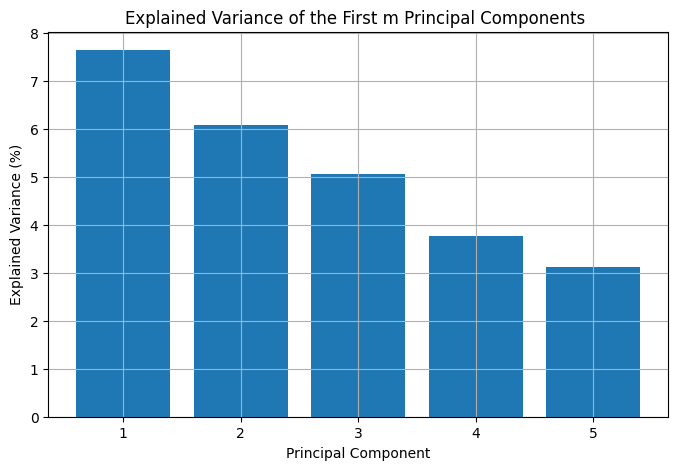

Total explained variance by m PCs (%): 25.66138070440498


In [14]:
# PCA with all components
pca_full = PCA()
pca_full.fit(responses_ft_pp)

# Cumulative explained variance
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# m' = smallest number of PCs explaining at least 33%
m_prime = np.argmax(cum_var >= 0.33) + 1

# Final m
m = min(m_prime, 5)

print("m' =", m_prime)
print("m =", m)

explained_var_pct = pca_full.explained_variance_ratio_[:m] * 100
constant_plotting = explained_var_pct.sum()

plt.figure(figsize=(8,5))
plt.bar(range(1, m+1), explained_var_pct)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance of the First m Principal Components ")
plt.grid()
plt.show()

print("Total explained variance by m PCs (%):",
      explained_var_pct.sum())



PC1:


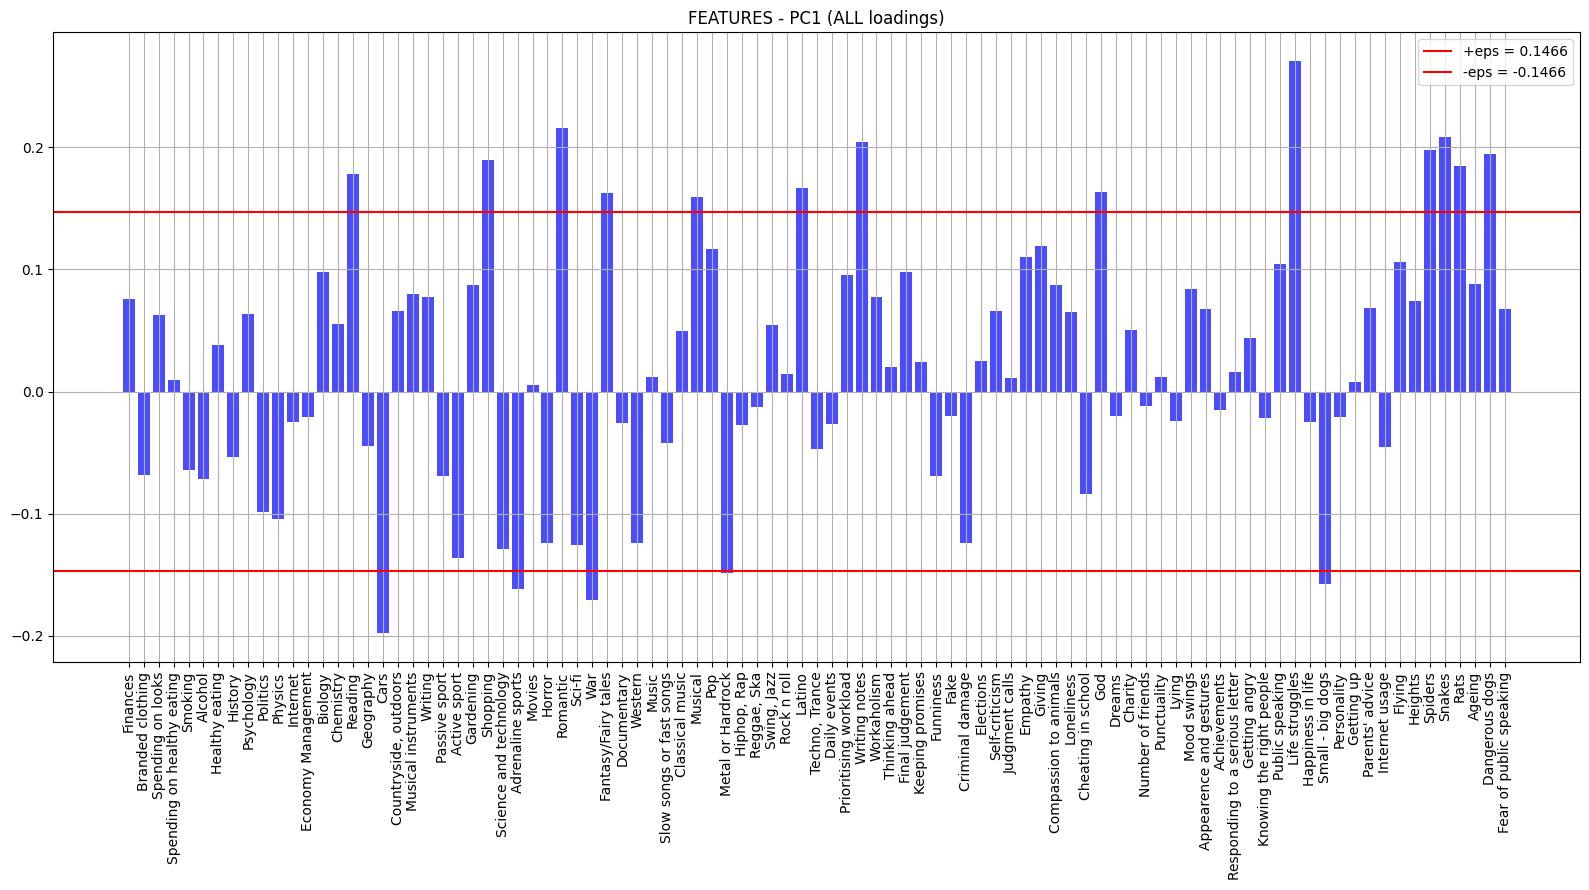

Features that exceed the threshold in PC1


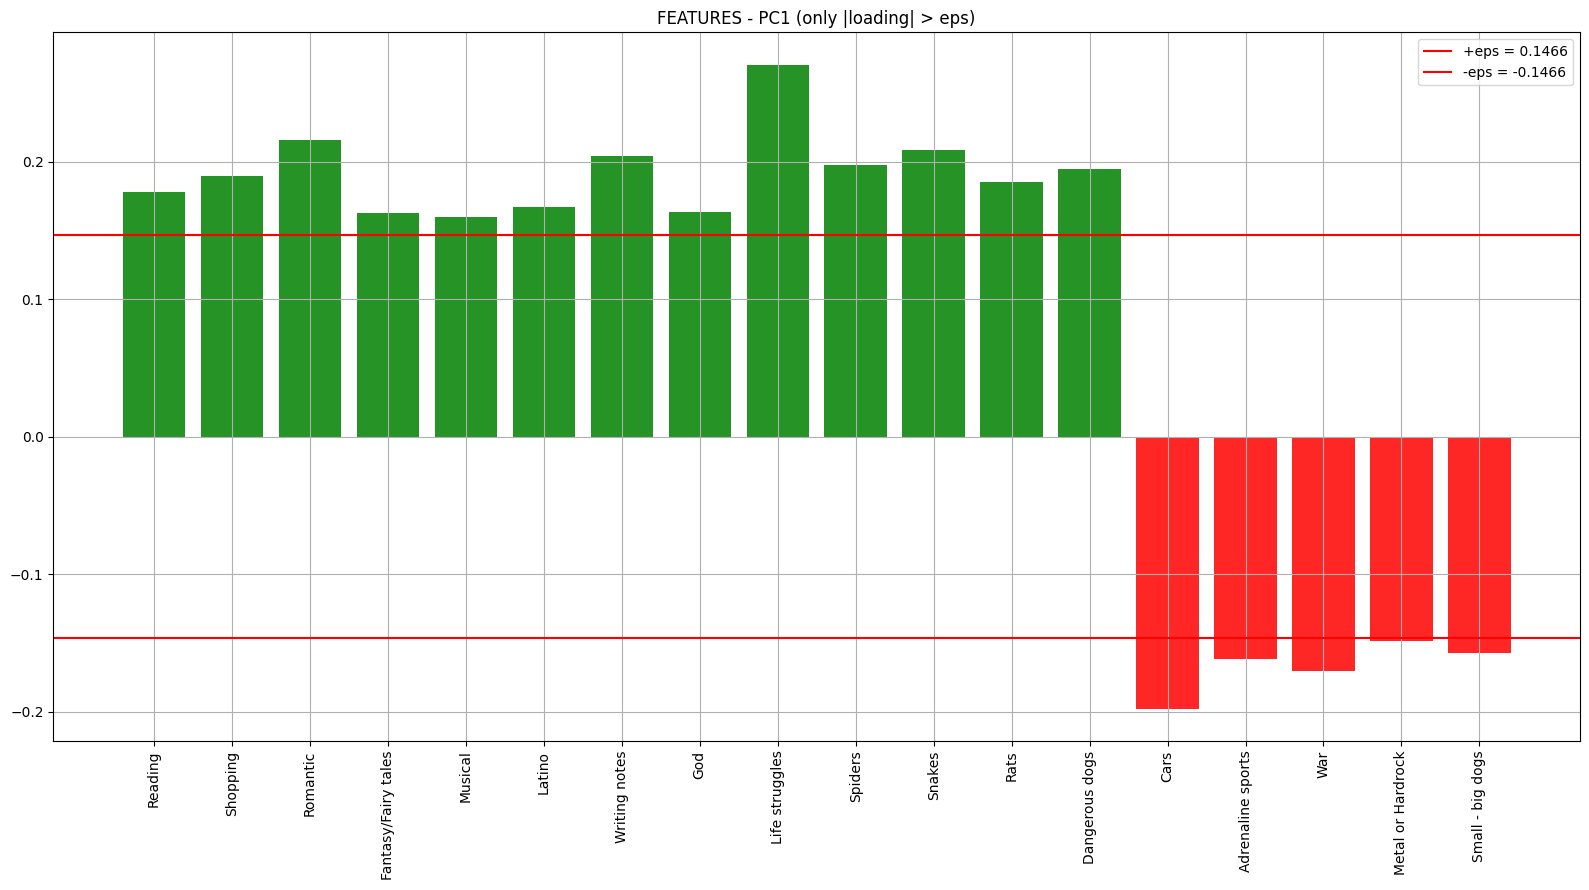

Max Positive features:
Index(['Life struggles', 'Romantic', 'Snakes', 'Writing notes', 'Spiders'], dtype='object')

Max negative features:
Index(['Cars', 'War', 'Adrenaline sports', 'Small - big dogs',
       'Metal or Hardrock'],
      dtype='object')

------------------------------------------------------------

PC2:


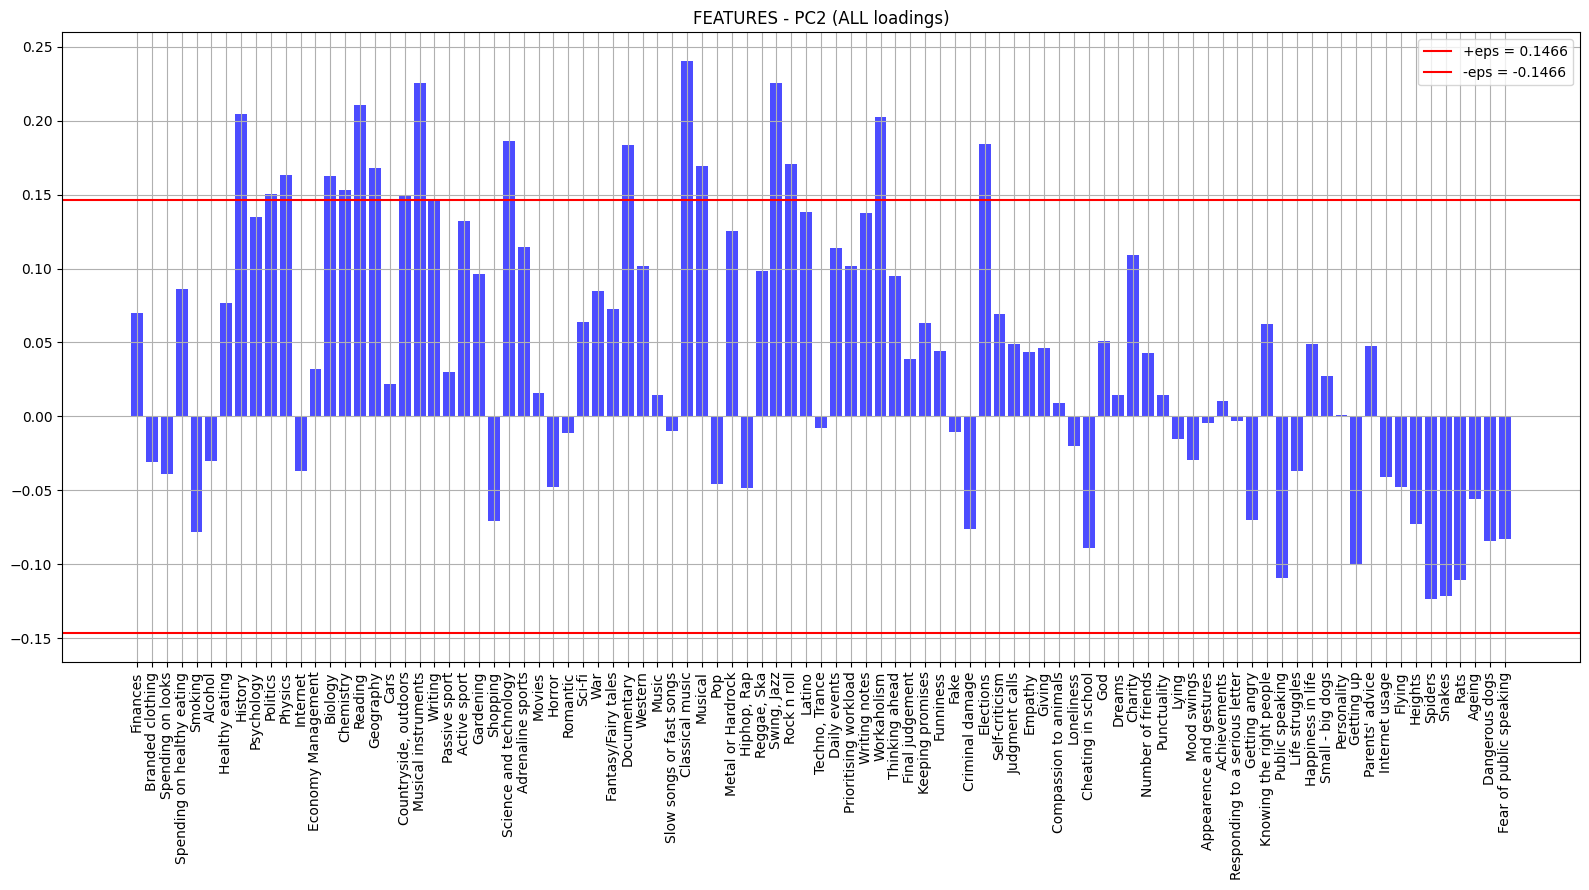

Features that exceed the threshold in PC2


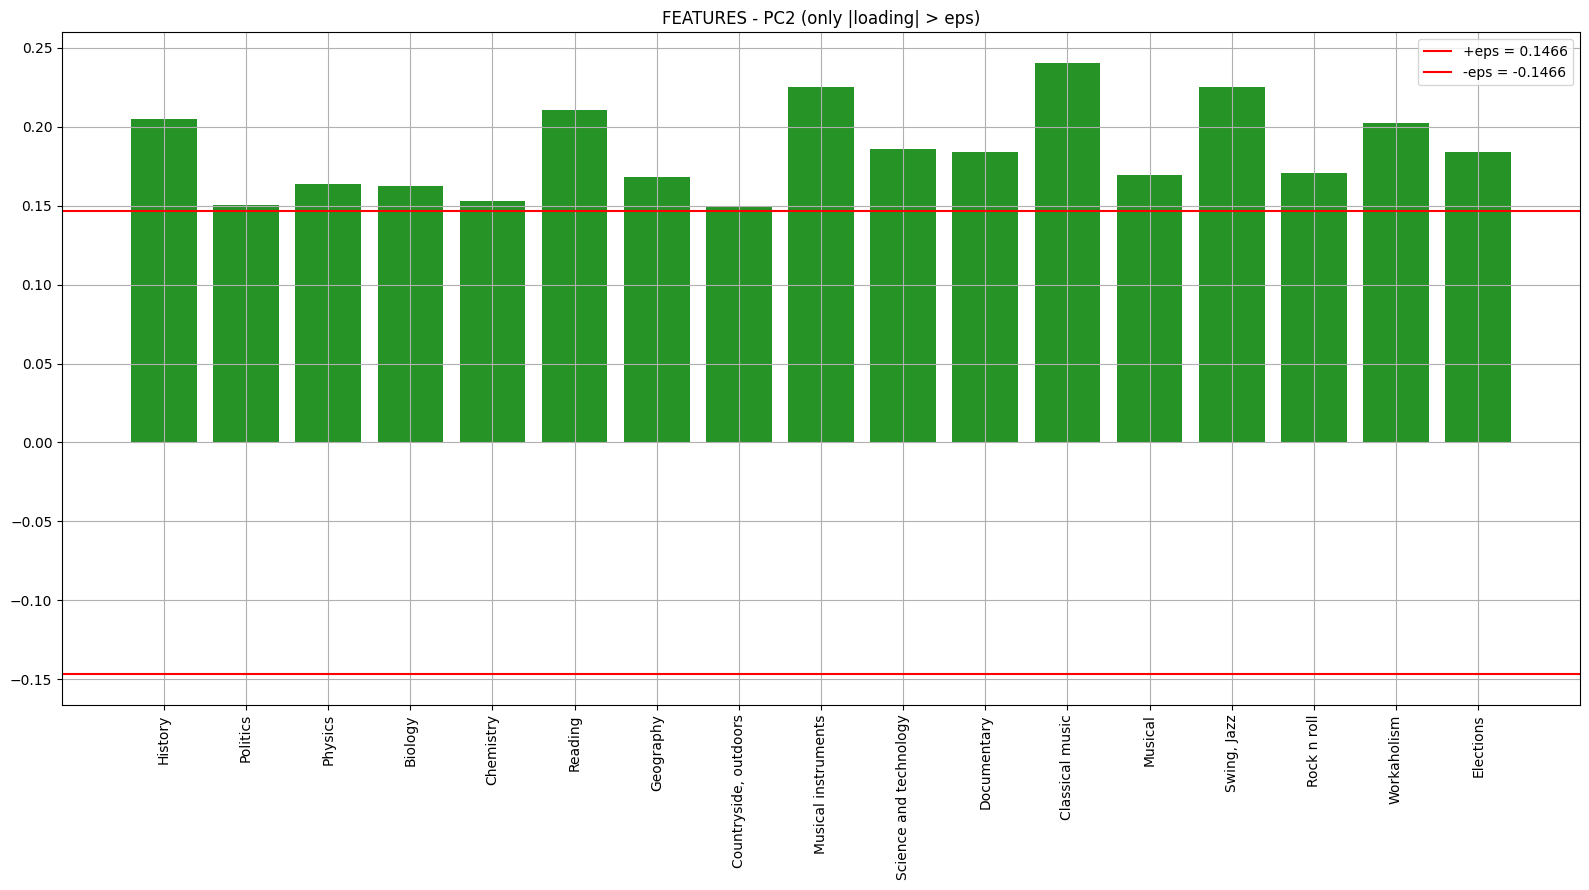

Max Positive features:
Index(['Classical music', 'Musical instruments', 'Swing, Jazz', 'Reading',
       'History'],
      dtype='object')

Max negative features:
None below -eps

------------------------------------------------------------

PC3:


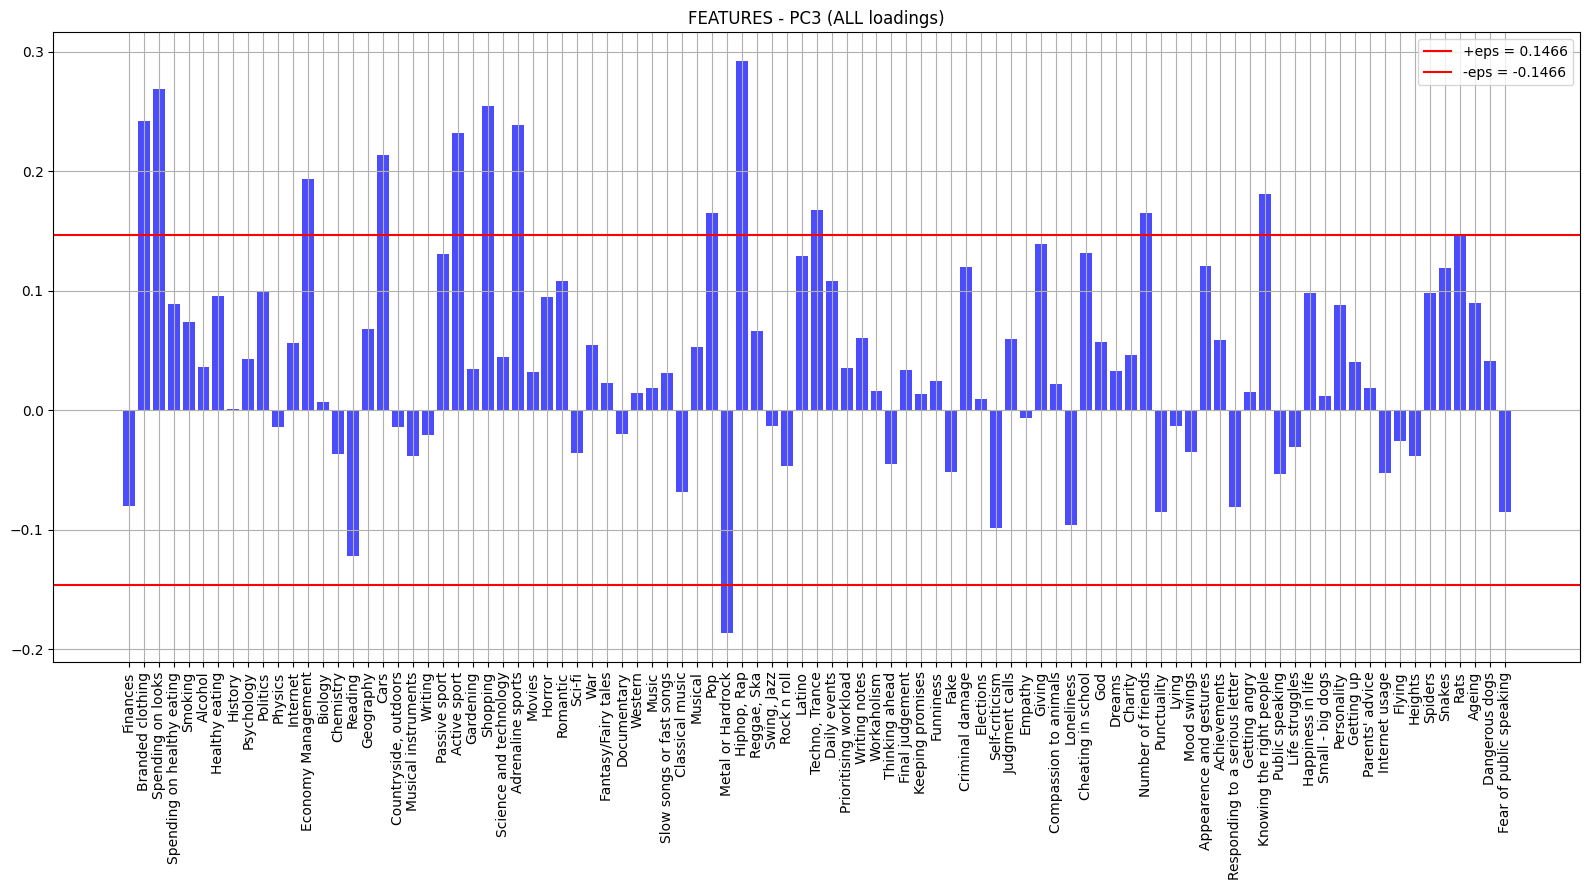

Features that exceed the threshold in PC3


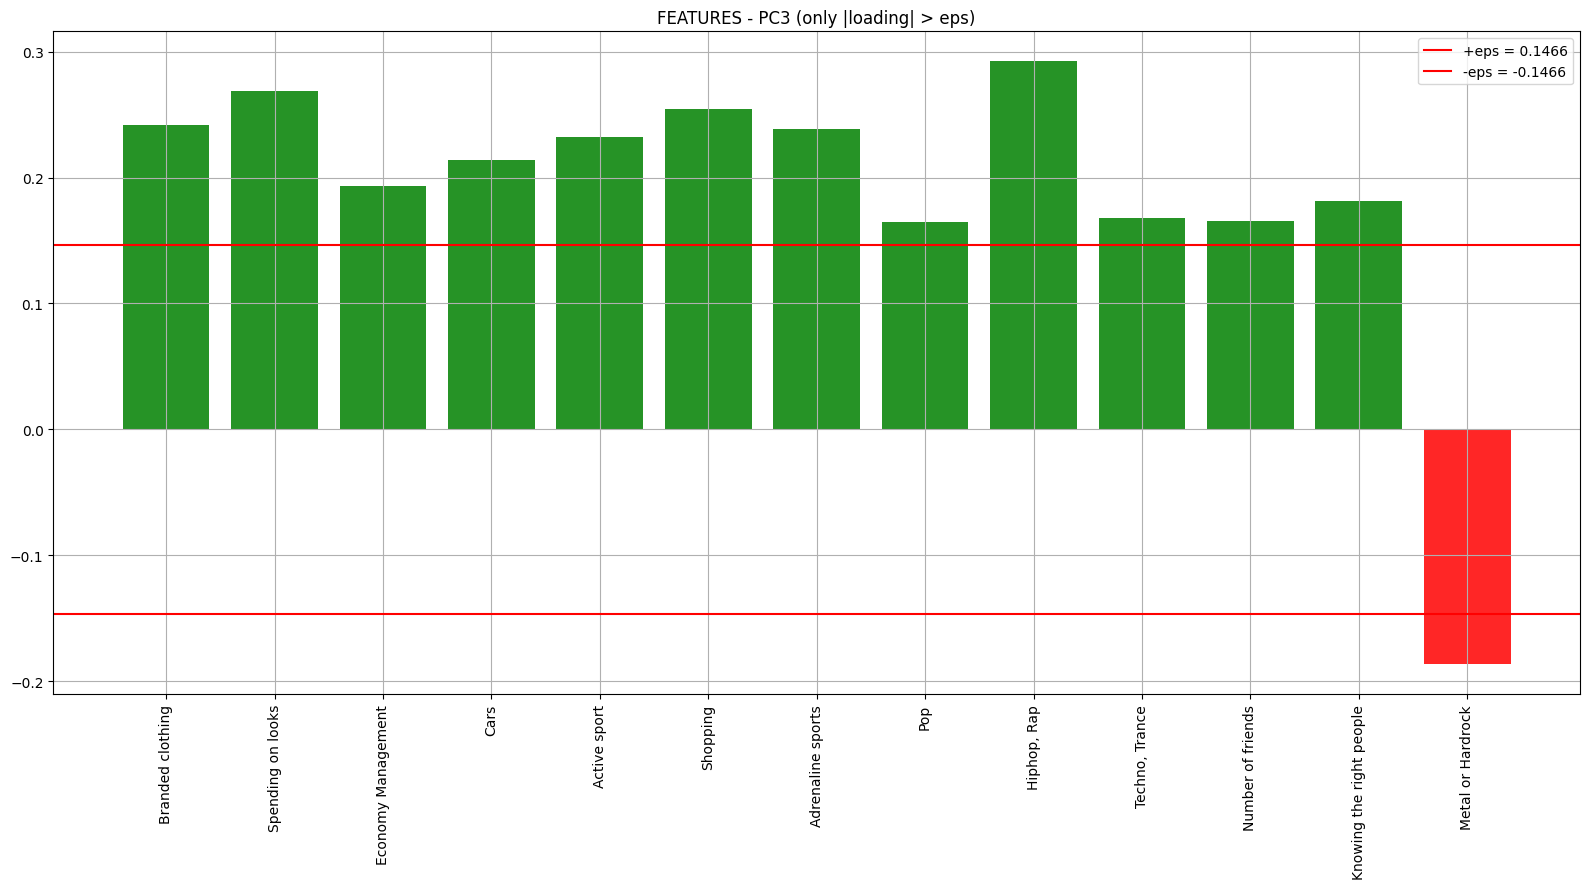

Max Positive features:
Index(['Hiphop, Rap', 'Spending on looks', 'Shopping', 'Branded clothing',
       'Adrenaline sports'],
      dtype='object')

Max negative features:
Index(['Metal or Hardrock'], dtype='object')

------------------------------------------------------------

PC4:


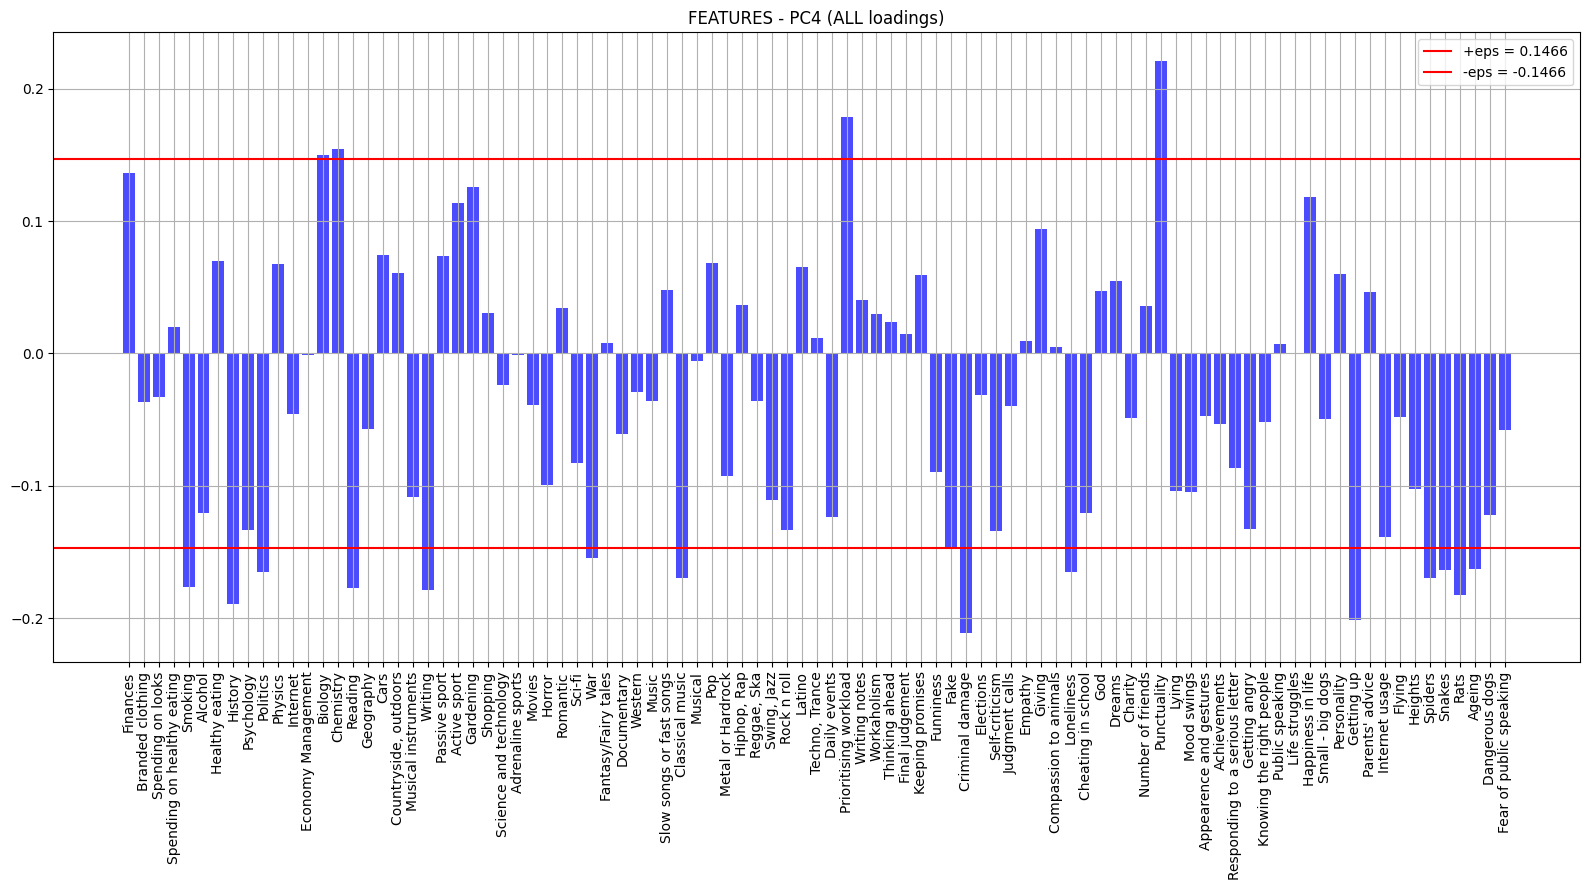

Features that exceed the threshold in PC4


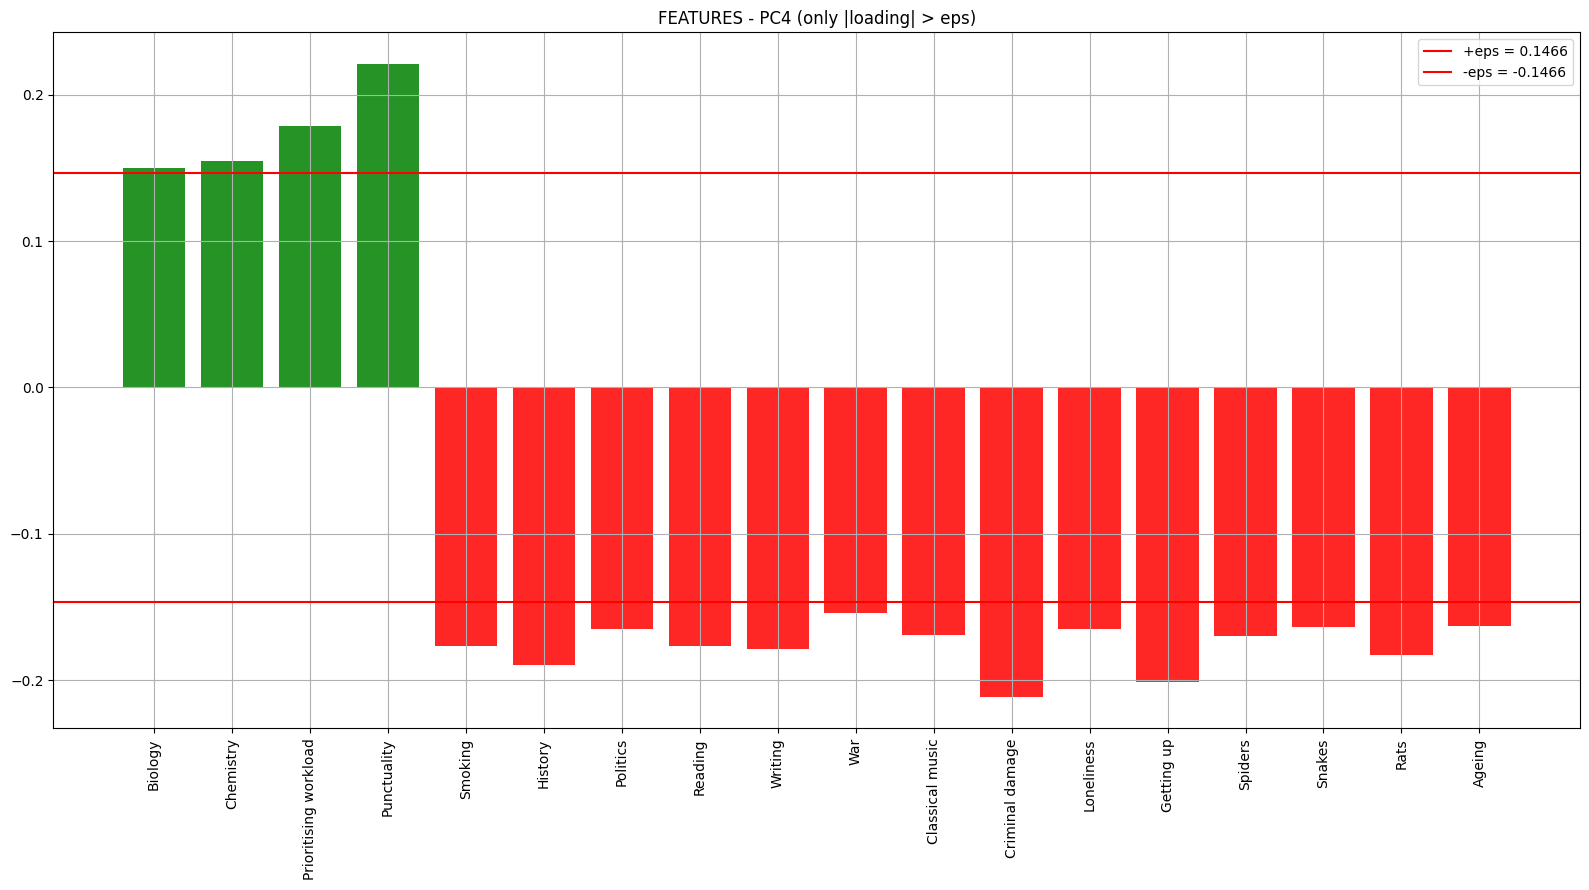

Max Positive features:
Index(['Punctuality', 'Prioritising workload', 'Chemistry', 'Biology'], dtype='object')

Max negative features:
Index(['Criminal damage', 'Getting up', 'History', 'Rats', 'Writing'], dtype='object')

------------------------------------------------------------

PC5:


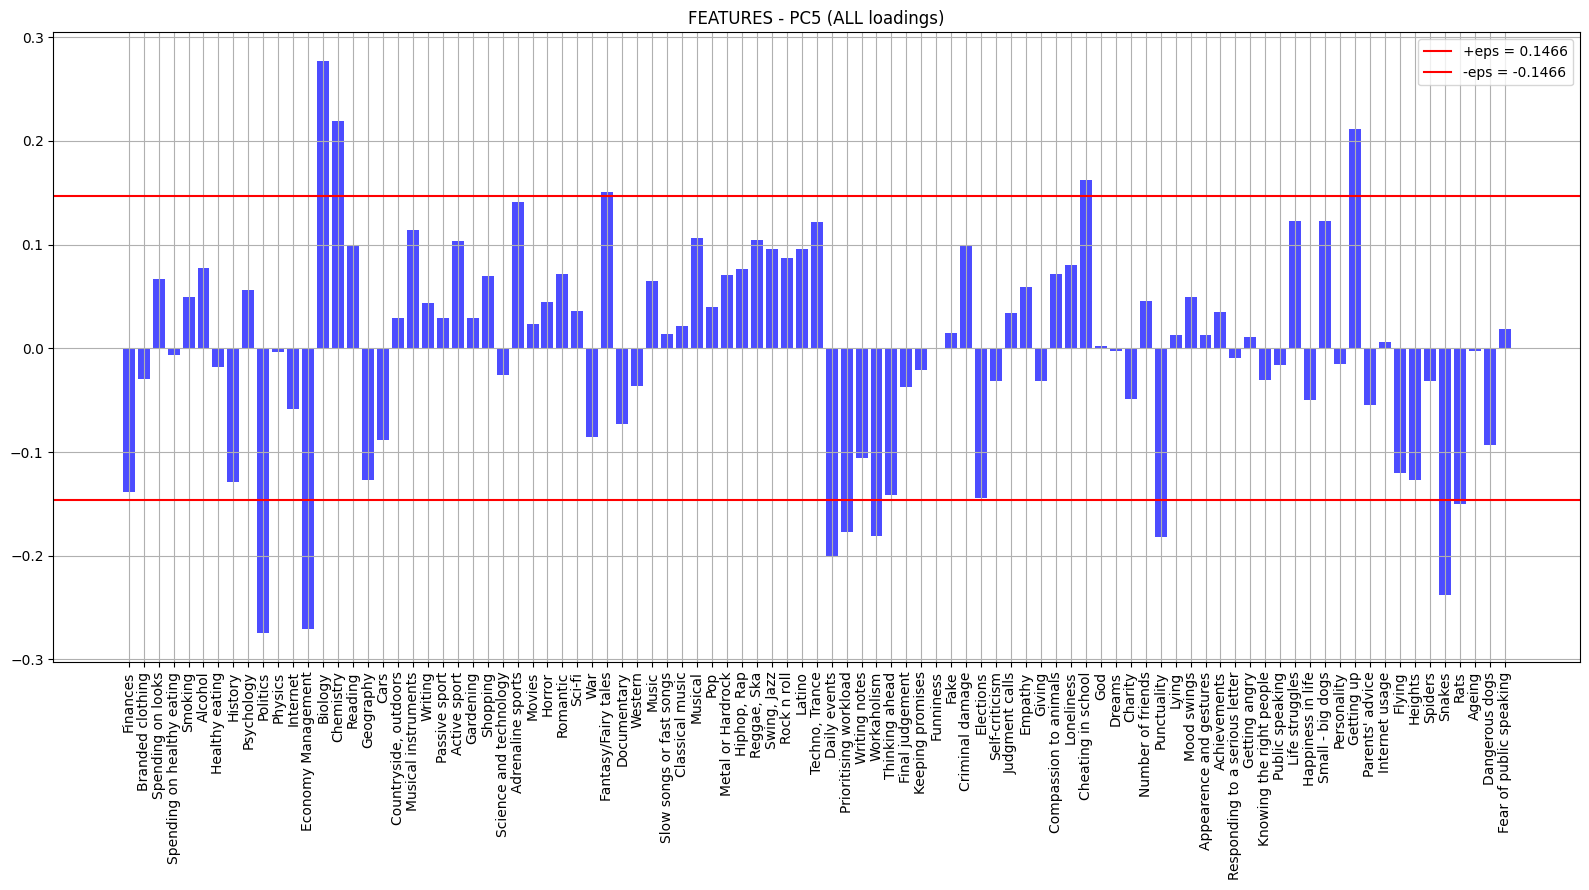

Features that exceed the threshold in PC5


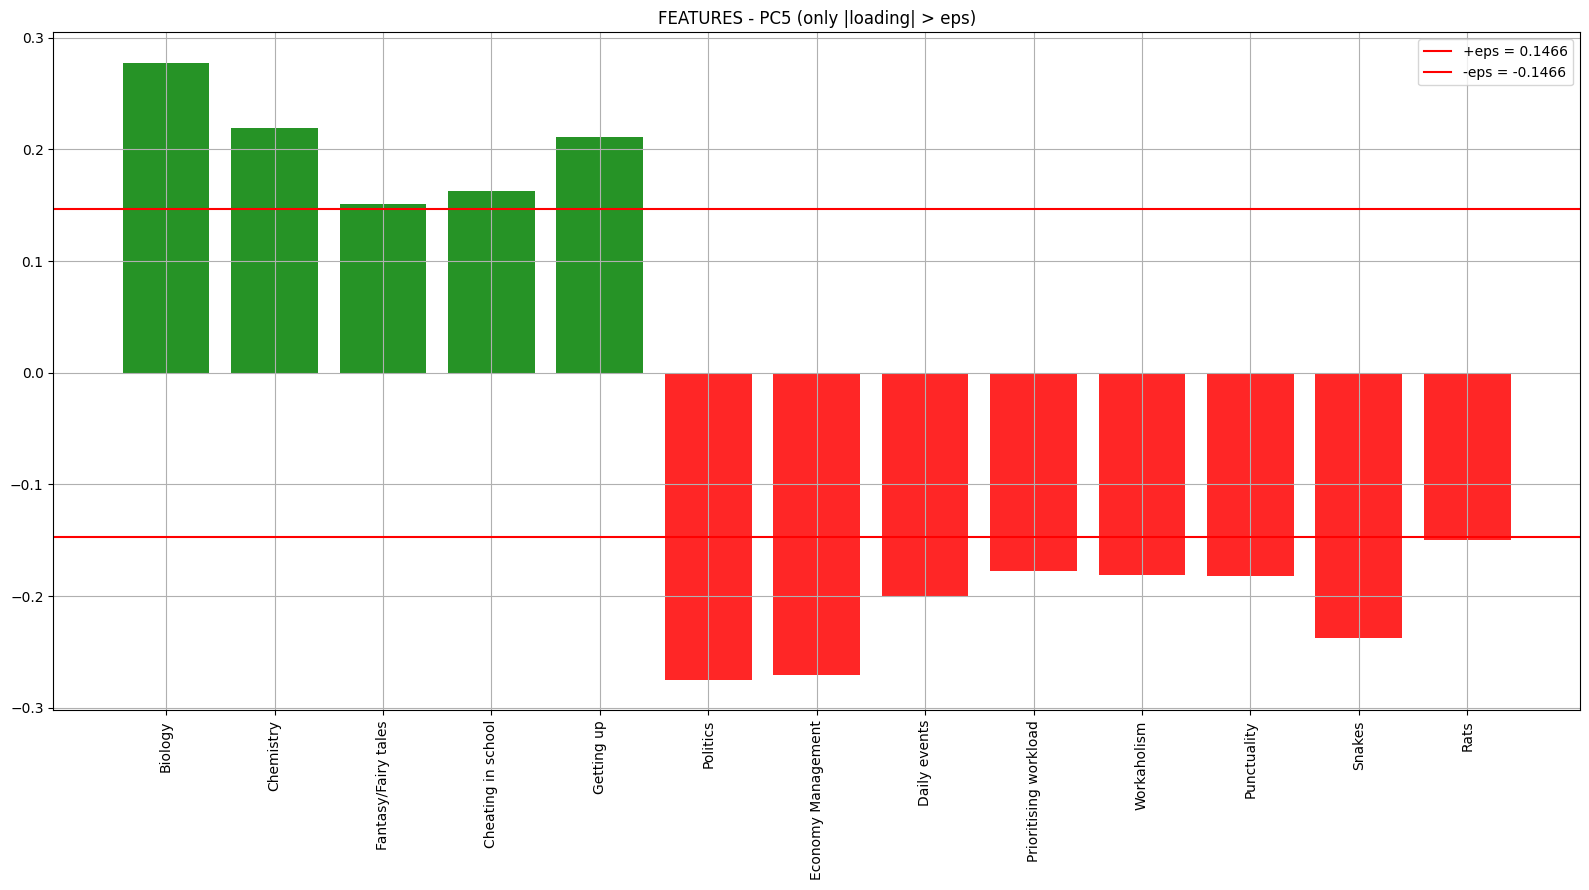

Max Positive features:
Index(['Biology', 'Chemistry', 'Getting up', 'Cheating in school',
       'Fantasy/Fairy tales'],
      dtype='object')

Max negative features:
Index(['Politics', 'Economy Management', 'Snakes', 'Daily events',
       'Punctuality'],
      dtype='object')

------------------------------------------------------------


In [15]:
X_df = responses_ft_pp  
feature_names = X_df.columns.tolist()
# PCA
pca_mm = PCA()
pca_mm.fit(X_df)

# Loadings (components)
loadings = pca_mm.components_

# THRESHOLD FORMULA
# eps = sqrt(2*(1/p))
eps_mm = np.sqrt(2 * (1 / pca_mm.n_features_in_))
 
# LOOP THROUGH PCs
for i, pc in enumerate(loadings[:m]):
    print(f"\nPC{i+1}:")

    # FULL BLUE PLOT (all features)
    
    plt.figure(figsize=(16, 9))
    plt.bar(X_df.columns, pc, color='blue', alpha=0.7)

    # horizontal threshold lines 
    plt.axhline(y=eps_mm, color='red', linestyle='-', label=f'+eps = {eps_mm:.4f}')
    plt.axhline(y=-eps_mm, color='red', linestyle='-', label=f'-eps = {-eps_mm:.4f}')

    plt.xticks(rotation=90)
    plt.title(f"FEATURES - PC{i+1} (ALL loadings)")
    plt.grid()
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

    # 2) FILTER FEATURES ABOVE THRESHOLD
    print(f"Features that exceed the threshold in PC{i+1}")

    above_threshold = [(feature_names[j], pc[j]) for j in range(len(pc)) if pc[j] > eps_mm]
    below_threshold = [(feature_names[j], pc[j]) for j in range(len(pc)) if pc[j] < -eps_mm]

    filtered_features = [f for f, v in (above_threshold + below_threshold)]
    filtered_values   = [v for f, v in (above_threshold + below_threshold)]
     
    plt.figure(figsize=(16, 9))

    # green for positive, red for negative
    colors = ['green' if val > 0 else 'red' for val in filtered_values]
    plt.bar(filtered_features, filtered_values, color=colors, alpha=0.85)

    plt.axhline(y=eps_mm, color='red', linestyle='-', label=f'+eps = {eps_mm:.4f}')
    plt.axhline(y=-eps_mm, color='red', linestyle='-', label=f'-eps = {-eps_mm:.4f}')

    plt.xticks(rotation=90)
    plt.title(f"FEATURES - PC{i+1} (only |loading| > eps)")
    plt.grid()
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

    # 4) TOP 5 POSITIVE / NEGATIVE FEATURES
  
    top_pos = sorted([j for j in range(len(pc)) if pc[j] > eps_mm],key=lambda x: pc[x],reverse=True)[:5]

    top_neg = sorted([j for j in range(len(pc)) if pc[j] < -eps_mm], key=lambda x: pc[x])[:5]

    print("Max Positive features:")
    if len(top_pos) > 0:
        print(X_df.columns[top_pos])
    else:
        print("None above +eps")

    print("\nMax negative features:")
    if len(top_neg) > 0:
        print(X_df.columns[top_neg])
    else:
        print("None below -eps")

    print("\n" + "-"*60)

#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

### Interpretation  :
We just chose the features that are the most influential features in defining the PC. The
higher block in these bars represents the feature that has the greatest influence on the PC
where the higher the value of the feature, the more it contributes to defining the direction of
the PC.



#### PC1: Reflective vs Action

Positive Features:
Life struggles, Romantic, Reading, Writing notes, Dangerous dogs

Negative Features:
Cars, PC, War, Actio, Adrenaline sports

Interpretation:
This component reflects a contrast between reflective, emotionally oriented tendencies and action-driven, thrill-seeking behaviors. High scores on PC1 indicate individuals who are more introspective, emotionally aware, and inclined toward reflective activities such as reading, writing, and romantic interests. Conversely, low scores are associated with preferences for fast-paced, technology-oriented, and adrenaline-related activities. Overall, PC1 distinguishes reflective and emotionally engaged individuals from those oriented toward action, excitement, and stimulation.

#### PC2: Intellectual & Traditional Orientation

Positive Features: Workaholism, History, Reading, Religion, Opera

Interpretation:
This component captures an orientation toward intellectual engagement, discipline, and traditional cultural values. High scores on PC2 are associated with strong interests in reading, history, and classical cultural domains such as religion and opera, combined with a tendency toward work commitment and perseverance. It reflects individuals who value knowledge, structure, and long-term effort, and who are inclined toward reflective, tradition-oriented, and intellectually demanding activities rather than purely entertainment-driven ones.

#### PC3: Consumerism & Social Image

Positive Features:
Spending on looks, Shopping , Shopping centres , Celebrities , Economy Management

Negative Features:
Metal or Hardrock
 
Interpretation:
This component represents a consumer-oriented and image-focused lifestyle. High positive loadings indicate strong interest in shopping, personal appearance, celebrity culture, and economic management, suggesting individuals who value consumption, trends, and social visibility. The negative loading on metal or hard rock reflects a contrast with alternative or countercultural tastes. High scores on PC3 describe people oriented toward mainstream consumer culture and outward social image rather than non-conventional cultural preferences

#### PC4: Lifestyle Flexibility vs Discipline

Positive Features:
Alternative, Reading,  Smoking , Getting up , Theatre

Negative Features:
Punctuality , Mathematics , Prioritising workload ,  pC, Finances

Interpretation:
The fourth principal component contrasts lifestyle-oriented and flexible behaviors with structured and disciplined habits. High positive scores are associated with cultural interests, flexible routines, and experiential activities, while negative scores reflect punctuality, analytical orientation, workload prioritization, and financial responsibility. Overall, PC4 captures a lifestyle flexibility versus discipline dimension, distinguishing experience-driven profiles from highly organized and task-focused individuals.

#### PC5: Beliefs vs Routine

Positive Features:
God, Religion , Final judgement , Biology , Techno Trance

Negative Features:
Punctuality , Workaholism , Prioritising workload , Writing notes , Thinking ahead

Interpretation:
PC5 highlights a contrast between spiritual or existential orientation and pragmatic, efficiency-driven behavior. High scores reflect stronger religious beliefs, interest in existential themes, and experiential domains such as music and biology. Low scores indicate structured planning, punctuality, and productivity-focused habits. This component distinguishes value-driven, reflective worldviews from highly organized, future-oriented pragmatism.

#### Write the code for visualizing the score graph (with PC names on the axis):

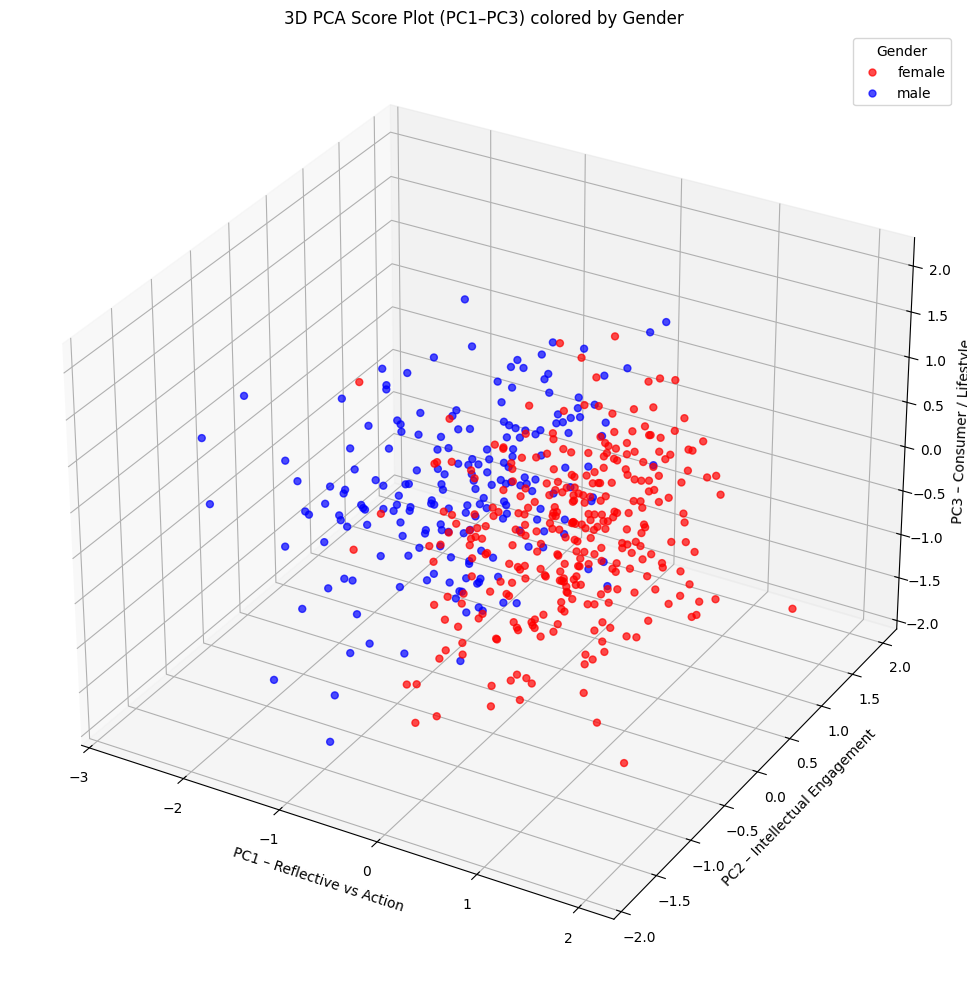

In [40]:
pca_m = PCA(n_components=m)
responses_ft_pca = pca_m.fit_transform(responses_ft_pp)
# Gender is taken ONLY as an external label (not used in PCA)
gender = responses_lb["Gender"]

# Map values -> readable names 
gender_labels = {
    "female": "female",
    "male": "male"
}

# Fixed colors
gender_colors = {
    "female": "red",
    "male": "blue"
}

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection="3d")

# Plot each gender group separately
for val, label in gender_labels.items():
    idx = (gender == val)
    ax.scatter(
        responses_ft_pca[idx, 0],  # PC1
        responses_ft_pca[idx, 1],  # PC2
        responses_ft_pca[idx, 2],  # PC3
        color=gender_colors[val],
        alpha=0.7,
        s=25,
        label=label
    )

ax.set_xlabel("PC1 – Reflective vs Action")
ax.set_ylabel("PC2 – Intellectual Engagement")
ax.set_zlabel("PC3 – Consumer / Lifestyle")

ax.set_title("3D PCA Score Plot (PC1–PC3) colored by Gender")
ax.legend(title="Gender", loc="upper right")

plt.tight_layout()
plt.show()

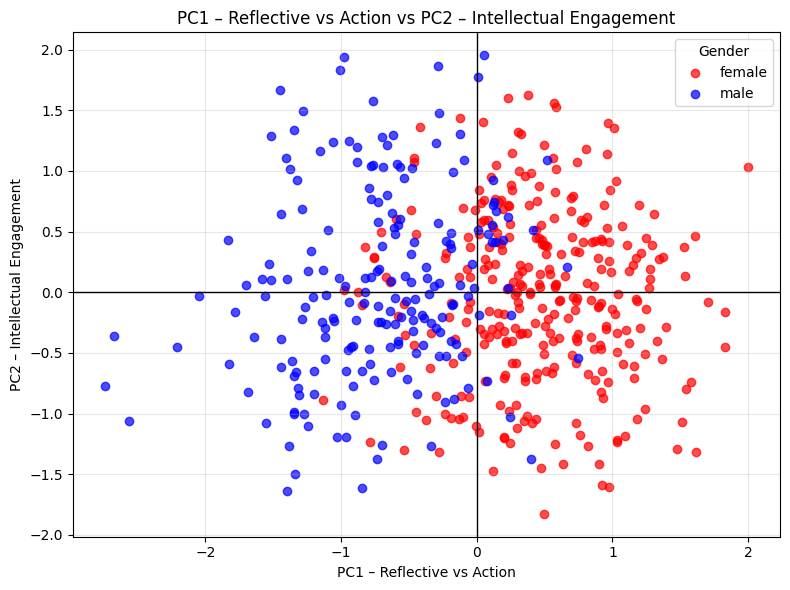

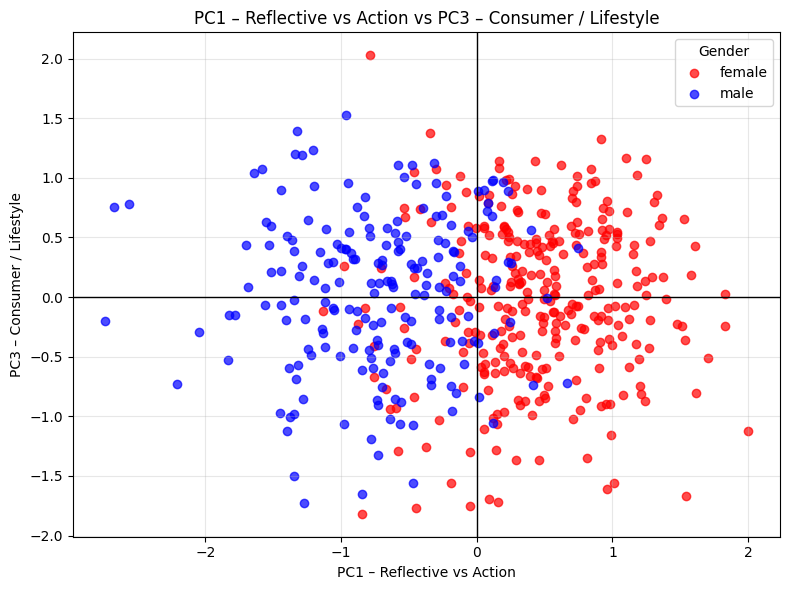

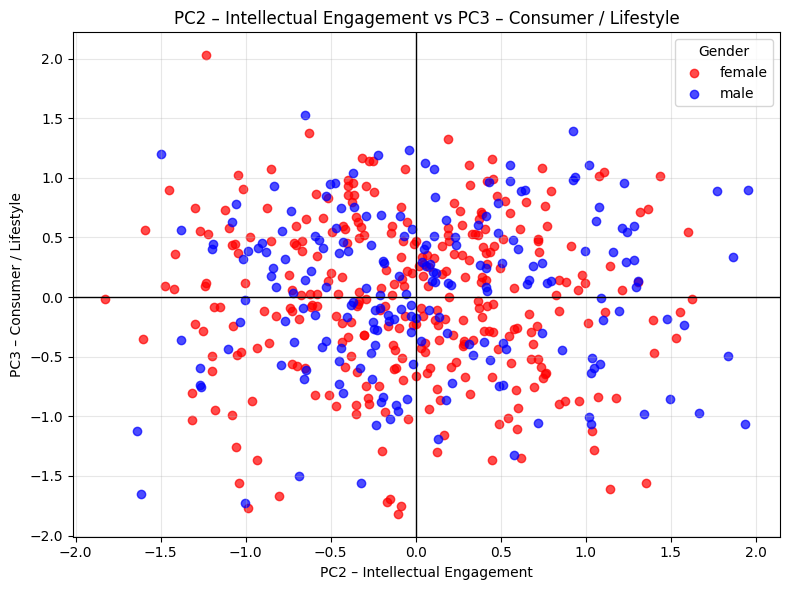

In [33]:
# --- Gender taken ONLY as external demographic label ---
gender = responses_lb["Gender"]

# Map values -> readable names
# (adapt if your dataset uses 0/1 instead of strings)
gender_labels = {
    "female": "female",
    "male": "male"
}

# Fixed colors
gender_colors = {
    "female": "red",
    "male": "blue"
}

pairs = [
    (0, 1, "PC1 – Reflective vs Action", "PC2 – Intellectual Engagement"),
    (0, 2, "PC1 – Reflective vs Action", "PC3 – Consumer / Lifestyle"),
    (1, 2, "PC2 – Intellectual Engagement", "PC3 – Consumer / Lifestyle")
]

for a, b, xlab, ylab in pairs:
    plt.figure(figsize=(8, 6))

    for val in gender_labels:
        idx = (gender == val)
        plt.scatter(
            responses_ft_pca[idx, a],
            responses_ft_pca[idx, b],
            color=gender_colors[val],
            alpha=0.7,
            label=gender_labels[val]
        )

    plt.axhline(0, color="black", linestyle="-", linewidth=1)
    plt.axvline(0, color="black", linestyle="-", linewidth=1)

    plt.xlabel(xlab)
    plt.ylabel(ylab)
    plt.title(f"{xlab} vs {ylab}")
    plt.legend(title="Gender")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [34]:
responses_lb['Gender'].value_counts()

Gender
female    309
male      197
Name: count, dtype: int64

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

In [19]:
# [write the code here]
random_state = random_seed
# Use the PCA representation for clustering
Y_mm = responses_ft_pca   # (n_samples, m)

km_list = []
silcoeff_list = []
k_list = list(range(3, 11))

for i in range(len(k_list)):
    k = k_list[i]
    print(f'**************** START K-MEANS WITH k={k} ****************')
    print('Computing...')

    km = KMeans(n_clusters=k, n_init=10, random_state=random_seed)
    km.fit(Y_mm)

    km_list.append(km)
    silcoeff_list.append(silhouette_score(Y_mm, km.labels_))

    print(f'**************** END K-MEANS WITH k={k} ****************')
    print('')

# Best k (max silhouette score)
i_best = int(np.argmax(silcoeff_list))
k_best = k_list[i_best]
km_mm = km_list[i_best]
best_score = silcoeff_list[i_best]
i_best = np.argmax(silcoeff_list)

print('')
print('**************** RESULTS OF THE SEARCH... ****************')
print(f'BEST SILHOUETTE SCORE: {best_score} --> k = {k_best}')
print('**********************************************************')

**************** START K-MEANS WITH k=3 ****************
Computing...
**************** END K-MEANS WITH k=3 ****************

**************** START K-MEANS WITH k=4 ****************
Computing...
**************** END K-MEANS WITH k=4 ****************

**************** START K-MEANS WITH k=5 ****************
Computing...
**************** END K-MEANS WITH k=5 ****************

**************** START K-MEANS WITH k=6 ****************
Computing...
**************** END K-MEANS WITH k=6 ****************

**************** START K-MEANS WITH k=7 ****************
Computing...
**************** END K-MEANS WITH k=7 ****************

**************** START K-MEANS WITH k=8 ****************
Computing...
**************** END K-MEANS WITH k=8 ****************

**************** START K-MEANS WITH k=9 ****************
Computing...
**************** END K-MEANS WITH k=9 ****************

**************** START K-MEANS WITH k=10 ****************
Computing...
**************** END K-MEANS WITH k=10 ********

k=3 is the best option with SILHOUETTE SCORE = 0.175

C:\Users\abdal\AppData\Local\Temp\ipykernel_16192\2587457407.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


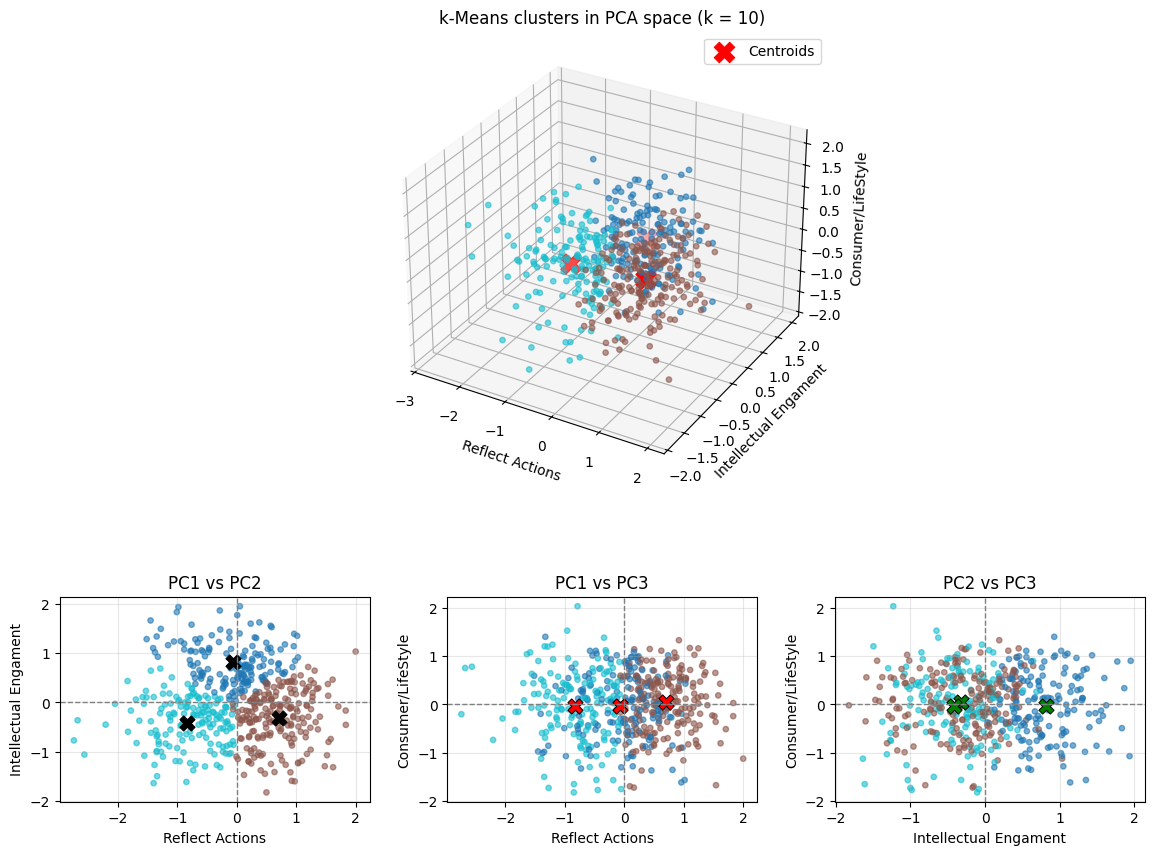

centroids shape: (3, 3)
len(pc_names): 3
pc_names: ['Reflect Actions', 'Intellectual Engament', 'Consumer/LifeStyle']


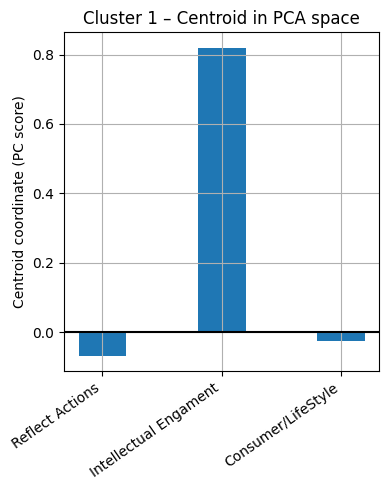

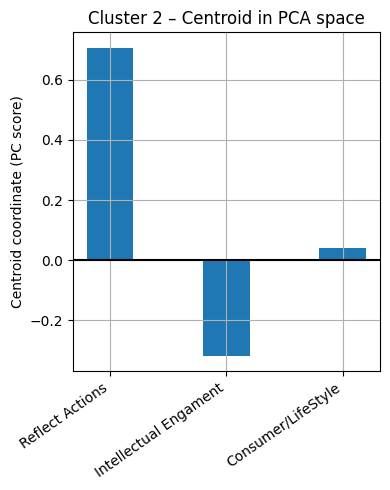

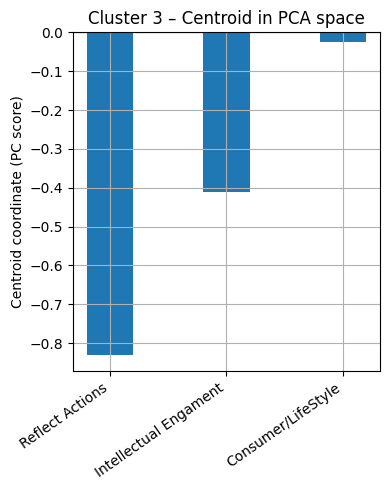

In [20]:
# responses_ft_pca : numpy array (n_samples, m)
# km_mm            : fitted KMeans model on responses_ft_pca (or first 3 PCs)
# k                : best number of clusters

# Use first 3 PCs for visualization
X3 = responses_ft_pca[:, :3]

labels = km_mm.labels_
centroids = km_mm.cluster_centers_[:, :3]  # centroids in PC space (first 3 dims)

# PC names 
pc_names = [
    "Reflect Actions",
    "Intellectual Engament",
    "Consumer/LifeStyle"
]

# ---- Figure layout: big 3D on top, 3 small 2D below ----
fig = plt.figure(figsize=(14, 10))
gs = GridSpec(2, 3, height_ratios=[2.2, 1], hspace=0.35, wspace=0.25)

# =========================
# Top: 3D scatter
# =========================
ax3d = fig.add_subplot(gs[0, :], projection="3d")

sc3d = ax3d.scatter(
    X3[:, 0], X3[:, 1], X3[:, 2],
    c=labels, cmap="tab10", alpha=0.6, s=15
)

# Centroids (big red X)
ax3d.scatter(
    centroids[:, 0], centroids[:, 1], centroids[:, 2],
    c="red", s=220, marker="X", edgecolor="red", linewidth=0.7, label="Centroids"
)

ax3d.set_xlabel(pc_names[0])
ax3d.set_ylabel(pc_names[1])
ax3d.set_zlabel(pc_names[2])
ax3d.set_title(f"k-Means clusters in PCA space (k = {k})")
ax3d.legend(loc="upper right")


ax12 = fig.add_subplot(gs[1, 0])
ax12.scatter(X3[:, 0], X3[:, 1], c=labels, cmap="tab10", alpha=0.6, s=15)
ax12.scatter(centroids[:, 0], centroids[:, 1], c="black", s=120, marker="X", edgecolor="black", linewidth=0.7)
ax12.axhline(0, color="grey", linestyle="--", linewidth=1)
ax12.axvline(0, color="grey", linestyle="--", linewidth=1)
ax12.set_xlabel(pc_names[0])
ax12.set_ylabel(pc_names[1])
ax12.set_title("PC1 vs PC2")
ax12.grid(alpha=0.3)


ax13 = fig.add_subplot(gs[1, 1])
ax13.scatter(X3[:, 0], X3[:, 2], c=labels, cmap="tab10", alpha=0.6, s=15)
ax13.scatter(centroids[:, 0], centroids[:, 2], c="red", s=120, marker="X", edgecolor="black", linewidth=0.7)
ax13.axhline(0, color="grey", linestyle="--", linewidth=1)
ax13.axvline(0, color="grey", linestyle="--", linewidth=1)
ax13.set_xlabel(pc_names[0])
ax13.set_ylabel(pc_names[2])
ax13.set_title("PC1 vs PC3")
ax13.grid(alpha=0.3)


ax23 = fig.add_subplot(gs[1, 2])
ax23.scatter(X3[:, 1], X3[:, 2], c=labels, cmap="tab10", alpha=0.6, s=15)
ax23.scatter(centroids[:, 1], centroids[:, 2], c="green", s=120, marker="X", edgecolor="black", linewidth=0.7)
ax23.axhline(0, color="grey", linestyle="--", linewidth=1)
ax23.axvline(0, color="grey", linestyle="--", linewidth=1)
ax23.set_xlabel(pc_names[1])
ax23.set_ylabel(pc_names[2])
ax23.set_title("PC2 vs PC3")
ax23.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print("centroids shape:", centroids.shape)
print("len(pc_names):", len(pc_names))
print("pc_names:", pc_names)

pc_names = pc_names[:centroids.shape[1]]

for c in range(centroids.shape[0]):
    plt.figure(figsize=(4,5))
    plt.bar(pc_names, centroids[c],width=0.4, alpha=1)
    plt.axhline(0, color='black')
    plt.title(f"Cluster {c+1} – Centroid in PCA space")
    plt.ylabel("Centroid coordinate (PC score)")
    plt.grid()
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()



Cluster 1 – Thinkers
This cluster is characterized by high intellectual engagement and a reflective orientation, indicating individuals who prioritize cognitive activities, learning, and thoughtful decision-making over impulsive action or consumer-oriented behaviors

Cluster 2 – Actives
This cluster is characterized by an action-oriented profile combined with higher consumer and lifestyle engagement. Individuals in this group tend to favor practical involvement and outward activities over reflective or purely intellectual pursuits. Their behavioral pattern suggests a preference for dynamic, experience-driven lifestyles, where action and consumption play a central role

Cluster 3 – Reserved
This cluster is characterized by a reflective profile combined with low consumer and lifestyle engagement. Individuals in this group tend to avoid action-driven and consumption-oriented behaviors, favoring a more restrained and inward-focused lifestyle. Their centroid position suggests a preference for simplicity and moderation, with limited emphasis on external activities or expressive consumption patterns

## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.



For the external evaluation of the clusters, we selected Age and Education as meaningful demographic labels, since they were not used during PCA or clustering and may reflect long-term lifestyle and behavioral differences.


In [21]:
# PCA scores clustered
X_pca = responses_ft_pca  

# Cluster labels from k-means
cluster = km_mm.labels_  

df = pd.read_csv("responses_hw.csv")
labels_df = df[["Age", "Education", "Gender"]]

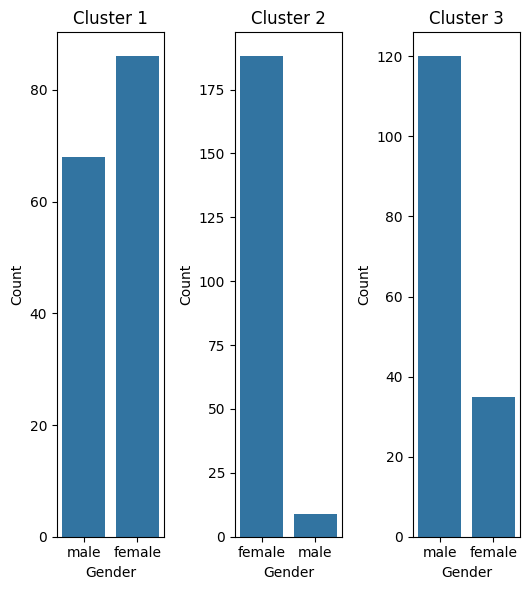

In [22]:
import seaborn as sns
label_name = "Gender"

label_series = responses_lb[label_name]     # <-- demographics/labels
cluster_labels = km_mm.labels_    
df_eval = pd.DataFrame({
    "cluster": cluster_labels,
    "label": label_series.values
})            

plt.figure(figsize=(5.4,6))

for c in sorted(df_eval["cluster"].unique()):
    plt.subplot(1, 3, c + 1)
    sns.countplot(
        x="label",
        data=df_eval[df_eval["cluster"] == c]
    )
    plt.title(f"Cluster {c+1}")
    plt.xlabel("Gender")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

Interpretation :

Gender shows a differentiated distribution across clusters.
Cluster 1 is predominantly female, suggesting that this behavioral profile is more common among women in the dataset. Cluster 2 shows a more balanced gender composition, indicating behaviors shared across genders. Cluster 3 has a higher proportion of males, pointing to a distinct male-dominated behavioral pattern. Since Gender was not used during clustering, these differences suggest that the clusters capture meaningful behavioral structures that correlate with demographic characteristics, supporting the validity of the clustering.

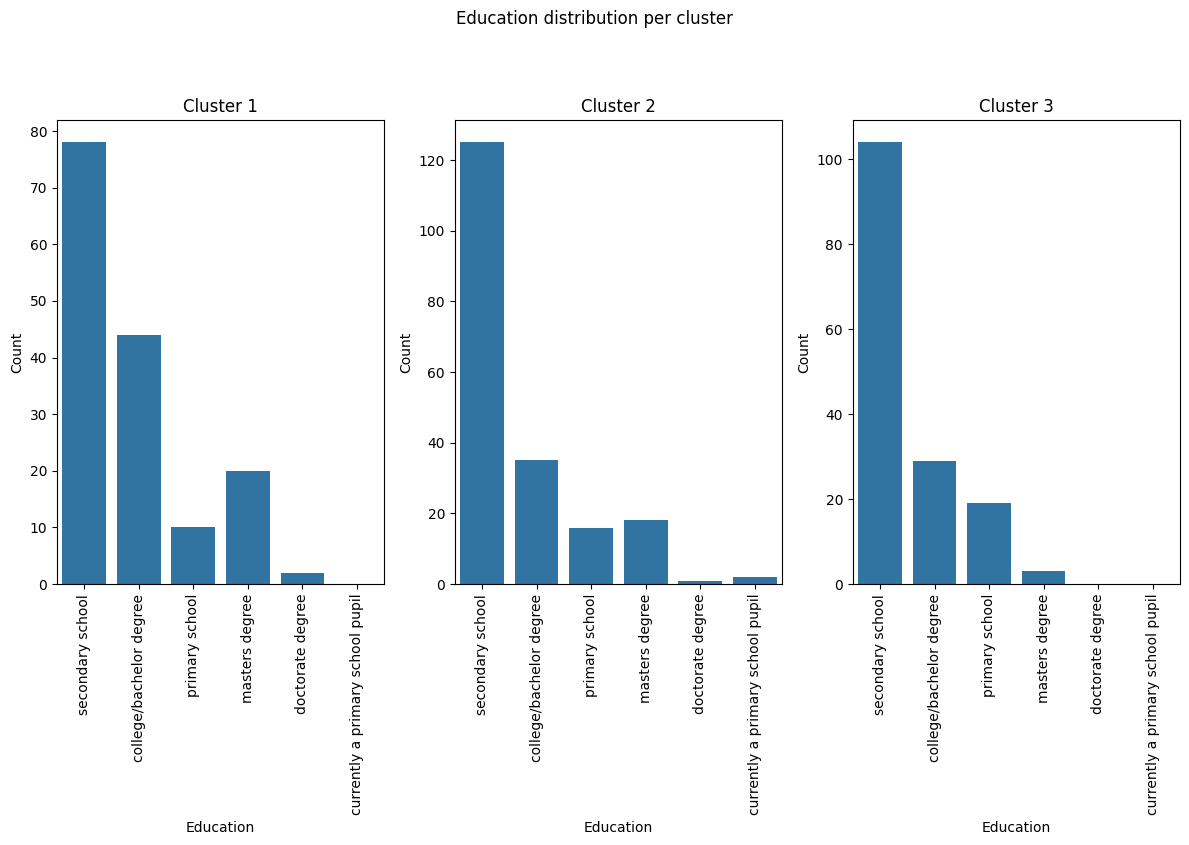

In [23]:
label_name = "Education"
label_series = responses_lb[label_name]   # demographic label
cluster_labels = km_mm.labels_            # k-means clusters (0..k-1)

df_eval = pd.DataFrame({
    "cluster": cluster_labels,
    "label": label_series.values
})

k = df_eval["cluster"].nunique()

plt.figure(figsize=(4*k, 8))

for c in sorted(df_eval["cluster"].unique()):
    plt.subplot(1, k, c+1)
    sns.countplot(x="label", data=df_eval[df_eval["cluster"] == c], order=df_eval["label"].value_counts().index)
    plt.title(f"Cluster {c+1}")
    plt.xlabel("Education")
    plt.ylabel("Count")
    plt.xticks(rotation=90)

plt.suptitle("Education distribution per cluster", y=1.05)
plt.tight_layout()
plt.show()             


Interpretation : 

Education levels differ noticeably across the three clusters, indicating that educational background helps characterize the identified groups. One cluster is dominated by individuals with secondary or undergraduate education, suggesting more practical or early-career profiles. Another cluster shows a higher concentration of participants with college or master’s degrees, reflecting stronger academic engagement. The third cluster presents a more mixed distribution, suggesting heterogeneous educational paths. Overall, education appears aligned with cluster structure and supports the meaningfulness of the clustering from an external demographic perspective.

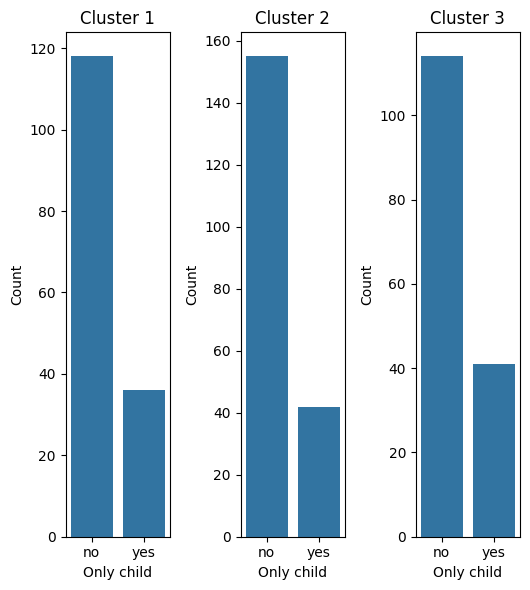

In [24]:
label_name = "Only child"
label_series = responses_lb[label_name]     # demographic label
cluster_labels = km_mm.labels_              # k-means cluster labels
# Build evaluation DataFrame
df_eval = pd.DataFrame({
    "cluster": cluster_labels,
    "label": label_series.values
})
plt.figure(figsize=(5.4, 6))
for c in sorted(df_eval["cluster"].unique()):
    plt.subplot(1, 3, c + 1)
    sns.countplot(
        x="label",
        data=df_eval[df_eval["cluster"] == c]
    )
    plt.title(f"Cluster {c+1}")
    plt.xlabel("Only child")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

Interpretation

The distribution of the “Only child” label differs across the three clusters, indicating variations in family structure among the identified groups. One cluster contains a higher proportion of individuals who are not only children, suggesting backgrounds with siblings and potentially greater early social interaction. Another cluster shows a relatively higher presence of only children, which may reflect different socialization experiences and independence. The remaining cluster presents a more balanced distribution. Overall, these differences suggest that family background contributes to distinguishing behavioral profiles captured by the clustering

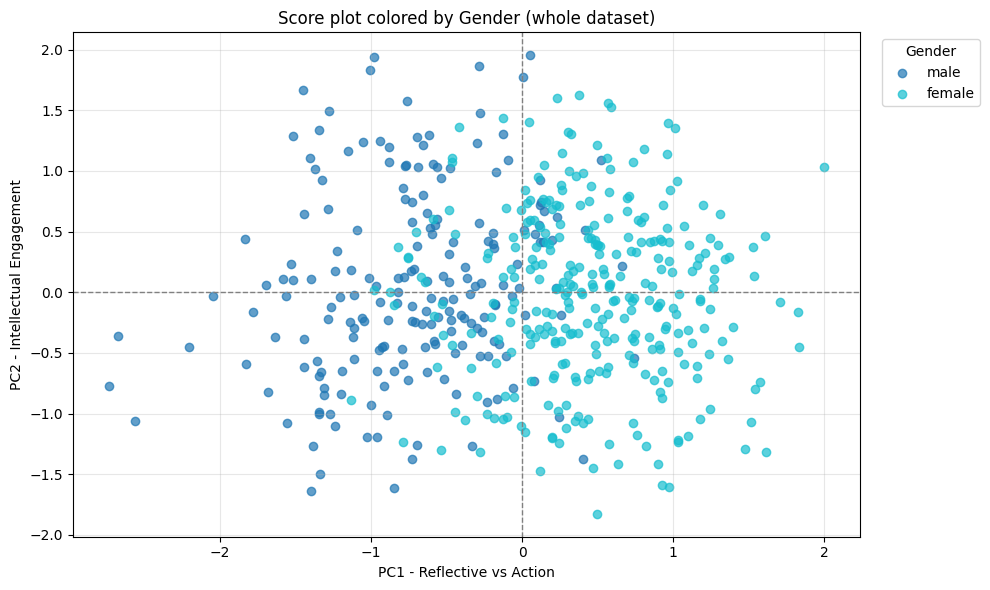

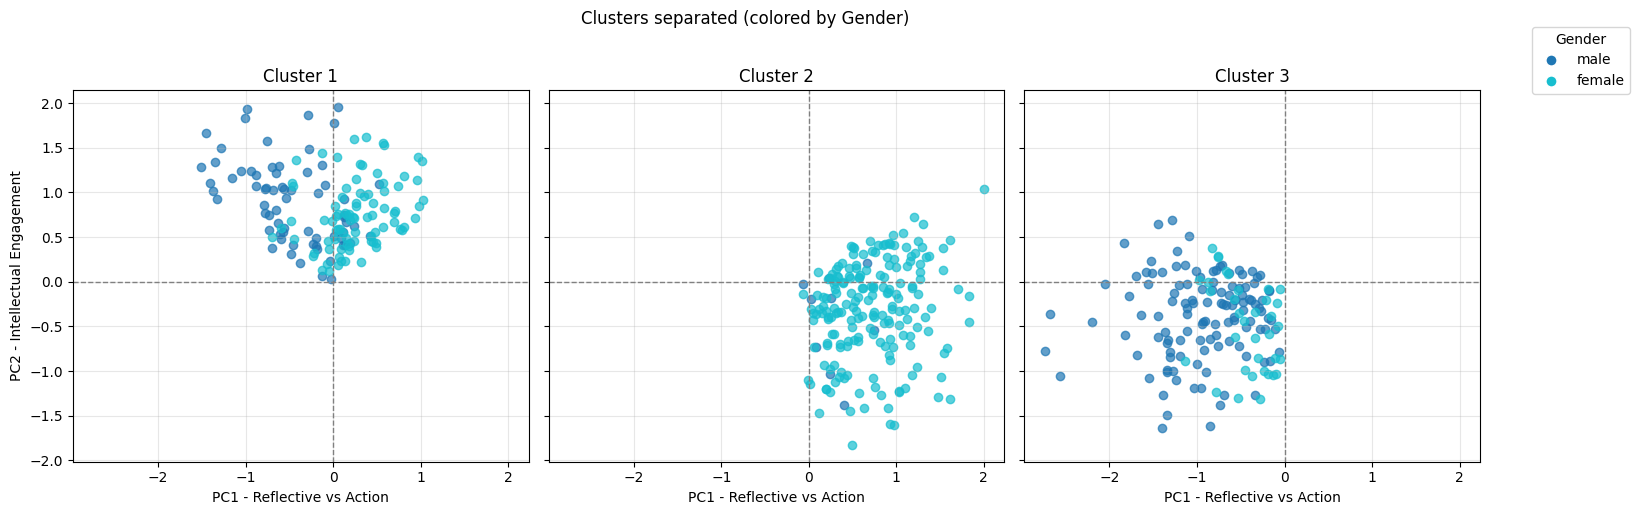

In [25]:
label_name = "Gender"   
y = responses_lb[label_name].values

X = responses_ft_pca[:, :2]     # PC1, PC2
clusters = km_mm.labels_
k = len(np.unique(clusters))

pc1_name = "PC1 - Reflective vs Action"
pc2_name = "PC2 - Intellectual Engagement"

# --- colors per label value -
unique_vals = pd.unique(y)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_vals)))
color_map = {val: col for val, col in zip(unique_vals, colors)}

# (1) Whole dataset plot
# =========================
plt.figure(figsize=(10, 6))
for val in unique_vals:
    idx = (y == val)
    plt.scatter(X[idx, 0], X[idx, 1], alpha=0.7, label=str(val), color=color_map[val])

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.xlabel(pc1_name); plt.ylabel(pc2_name)
plt.title(f"Score plot colored by {label_name} (whole dataset)")
plt.legend(title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# (2) One figure with subplots (one per cluster)
# =========================
fig, axes = plt.subplots(1, k, figsize=(5*k, 5), sharex=True, sharey=True)

if k == 1:
    axes = [axes]  # in case k=1, make it iterable

for c, ax in enumerate(axes):
    idx_cluster = (clusters == c)
    for val in unique_vals:
        idx = idx_cluster & (y == val)
        ax.scatter(X[idx, 0], X[idx, 1], alpha=0.7, color=color_map[val])
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"Cluster {c+1}")
    ax.set_xlabel(pc1_name)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(pc2_name)

# legend once 
handles = [plt.Line2D([0], [0], marker='o', color='w', label=str(val),
                      markerfacecolor=color_map[val], markersize=8)
           for val in unique_vals]
fig.legend(handles=handles, title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle(f"Clusters separated (colored by {label_name})", y=1.02)
plt.tight_layout()
plt.show()

#### Label Gender

The gender distribution shows partial imbalance across clusters but no strict separation. Some clusters contain a higher proportion of females, while others are more balanced. This indicates that gender is not a primary driver of the clustering, but it may weakly correlate with certain behavioral profiles captured by the PCA components.

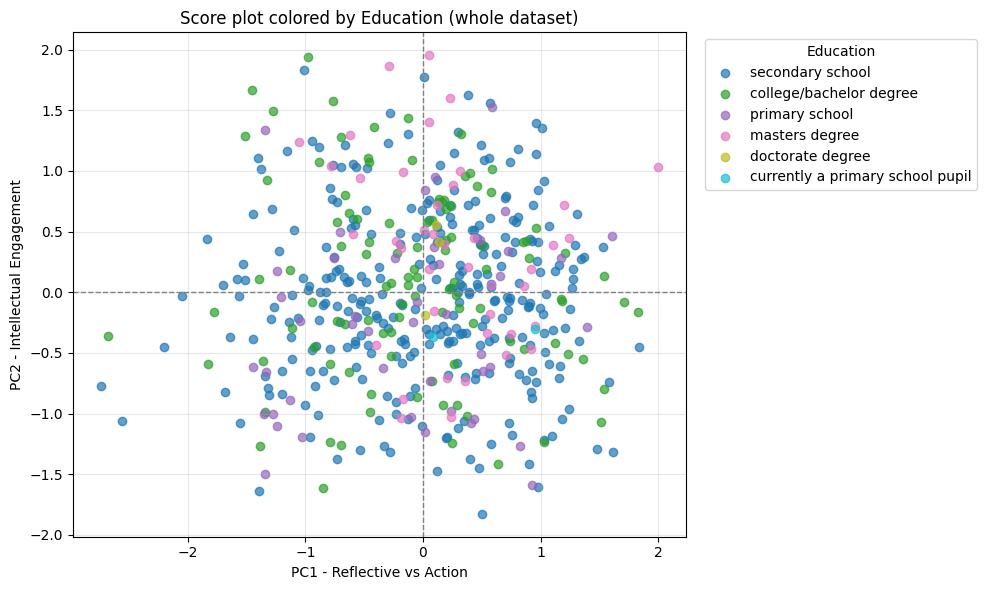

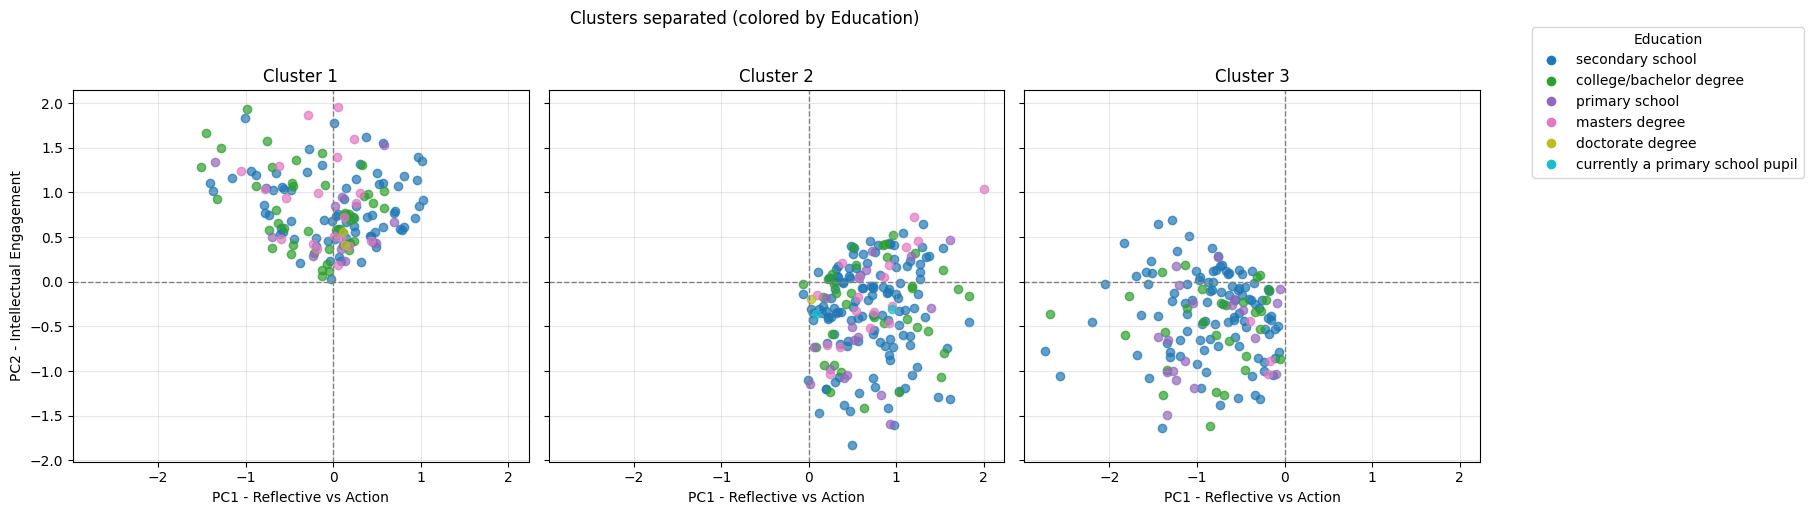

In [26]:
label_name = "Education"   
y = responses_lb[label_name].values

X = responses_ft_pca[:, :2]     # PC1, PC2
clusters = km_mm.labels_
k = len(np.unique(clusters))

pc1_name = "PC1 - Reflective vs Action"
pc2_name = "PC2 - Intellectual Engagement"

# --- colors per label value (consistent across all subplots) ---
unique_vals = pd.unique(y)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_vals)))
color_map = {val: col for val, col in zip(unique_vals, colors)}

# =========================
# (1) Whole dataset plot
# =========================
plt.figure(figsize=(10, 6))
for val in unique_vals:
    idx = (y == val)
    plt.scatter(X[idx, 0], X[idx, 1], alpha=0.7, label=str(val), color=color_map[val])

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.xlabel(pc1_name); plt.ylabel(pc2_name)
plt.title(f"Score plot colored by {label_name} (whole dataset)")
plt.legend(title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =========================
# (2) One figure with subplots (one per cluster)
# =========================
fig, axes = plt.subplots(1, k, figsize=(5*k, 5), sharex=True, sharey=True)

if k == 1:
    axes = [axes]  # in case k=1, make it iterable

for c, ax in enumerate(axes):
    idx_cluster = (clusters == c)
    for val in unique_vals:
        idx = idx_cluster & (y == val)
        ax.scatter(X[idx, 0], X[idx, 1], alpha=0.7, color=color_map[val])
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"Cluster {c+1}")
    ax.set_xlabel(pc1_name)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(pc2_name)

# legend once (not repeated)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=str(val),
                      markerfacecolor=color_map[val], markersize=8)
           for val in unique_vals]
fig.legend(handles=handles, title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle(f"Clusters separated (colored by {label_name})", y=1.02)
plt.tight_layout()
plt.show()

#### Label : Education

Education levels vary noticeably across clusters. One cluster is dominated by participants with secondary or bachelor education, while another shows a higher presence of higher education levels. This suggests that educational background contributes to differences in lifestyle, interests, or intellectual engagement, aligning with the PCA dimensions used for clustering.

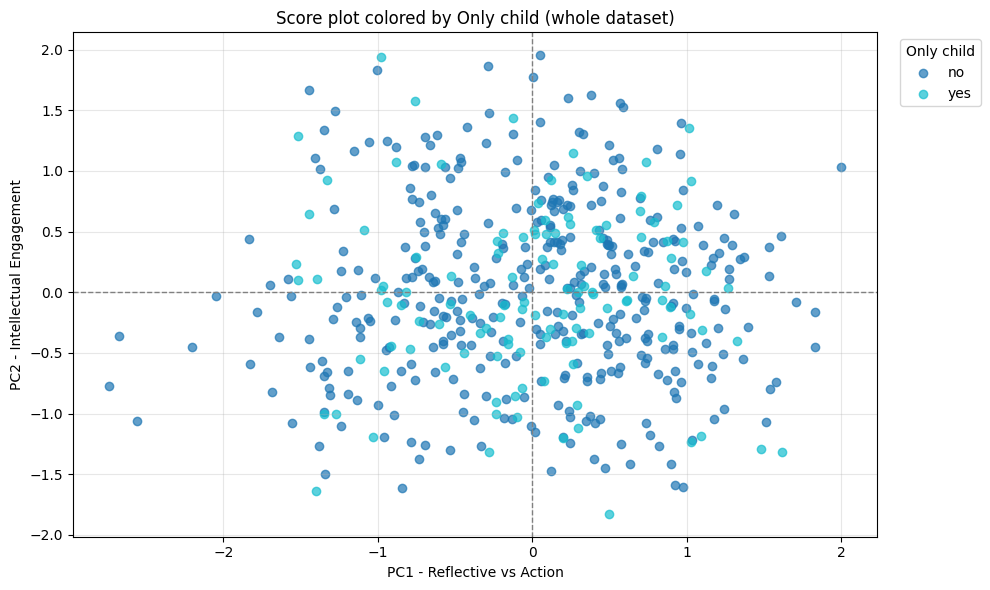

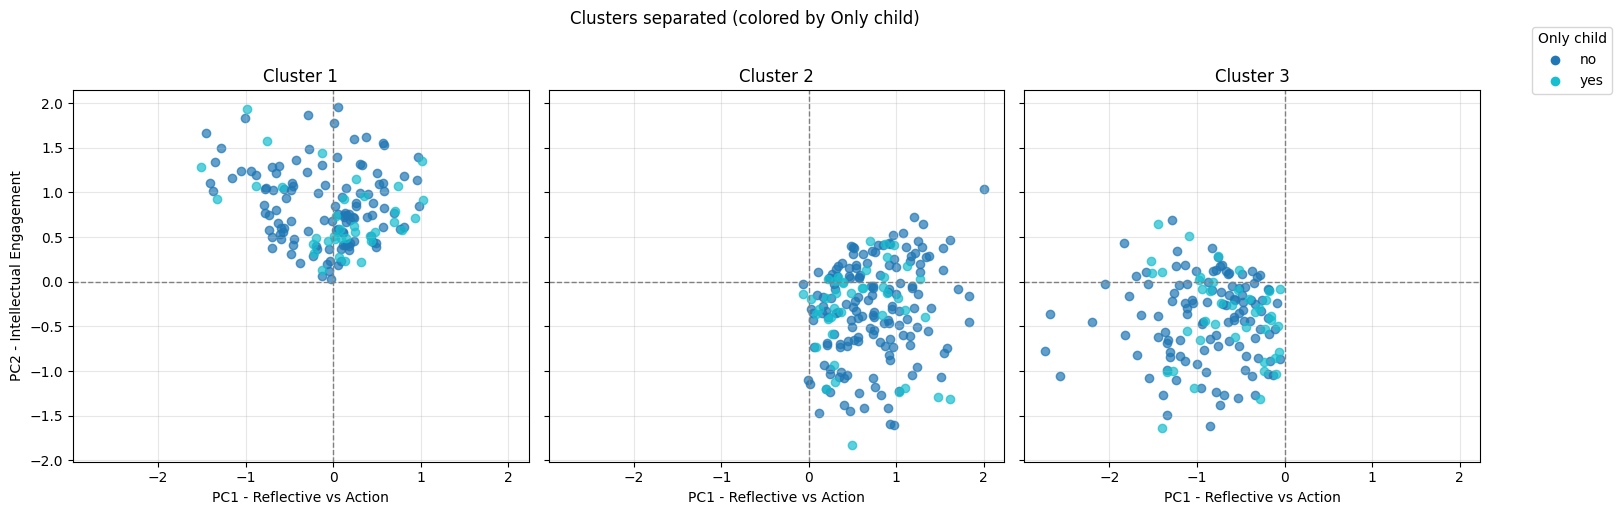

In [27]:
label_name = "Only child"   
y = responses_lb[label_name].values

X = responses_ft_pca[:, :2]     # PC1, PC2
clusters = km_mm.labels_
k = len(np.unique(clusters))

pc1_name = "PC1 - Reflective vs Action"
pc2_name = "PC2 - Intellectual Engagement"

# --- colors per label value (consistent across all subplots) ---
unique_vals = pd.unique(y)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_vals)))
color_map = {val: col for val, col in zip(unique_vals, colors)}

# (1) Whole dataset plot
# =========================
plt.figure(figsize=(10, 6))
for val in unique_vals:
    idx = (y == val)
    plt.scatter(X[idx, 0], X[idx, 1], alpha=0.7, label=str(val), color=color_map[val])

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.xlabel(pc1_name); plt.ylabel(pc2_name)
plt.title(f"Score plot colored by {label_name} (whole dataset)")
plt.legend(title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# (2) One figure with subplots (one per cluster)
# =========================
fig, axes = plt.subplots(1, k, figsize=(5*k, 5), sharex=True, sharey=True)

if k == 1:
    axes = [axes]  # in case k=1, make it iterable

for c, ax in enumerate(axes):
    idx_cluster = (clusters == c)
    for val in unique_vals:
        idx = idx_cluster & (y == val)
        ax.scatter(X[idx, 0], X[idx, 1], alpha=0.7, color=color_map[val])
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"Cluster {c+1}")
    ax.set_xlabel(pc1_name)
    ax.grid(alpha=0.3)

axes[0].set_ylabel(pc2_name)

# legend once (not repeated)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=str(val),
                      markerfacecolor=color_map[val], markersize=8)
           for val in unique_vals]
fig.legend(handles=handles, title=label_name, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle(f"Clusters separated (colored by {label_name})", y=1.02)
plt.tight_layout()
plt.show()

#### Label : Only Child

The distribution of “Only child” differs moderately between clusters. Some clusters show a higher proportion of only children, while others are dominated by participants with siblings. This implies that family background may influence personality traits or social behaviors reflected in the PCA space, although it is not a dominant separating factor.

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


In [28]:
# Overall silhouette score
from sklearn.metrics import silhouette_score, silhouette_samples
silhouette_avg = silhouette_score(X_pca, labels)
print(f"Average silhouette score (overall): {silhouette_avg:.4f}")

# Silhouette score for each sample
sample_silhouette_values = silhouette_samples(X_pca, labels)

# Average silhouette score per cluster
for i in range(k):
    cluster_silhouette_avg = sample_silhouette_values[labels == i].mean()
    print(f"Average silhouette score for cluster {i+1}: {cluster_silhouette_avg:.4f}")

Average silhouette score (overall): 0.1746
Average silhouette score for cluster 1: 0.1580
Average silhouette score for cluster 2: 0.1843
Average silhouette score for cluster 3: 0.1787


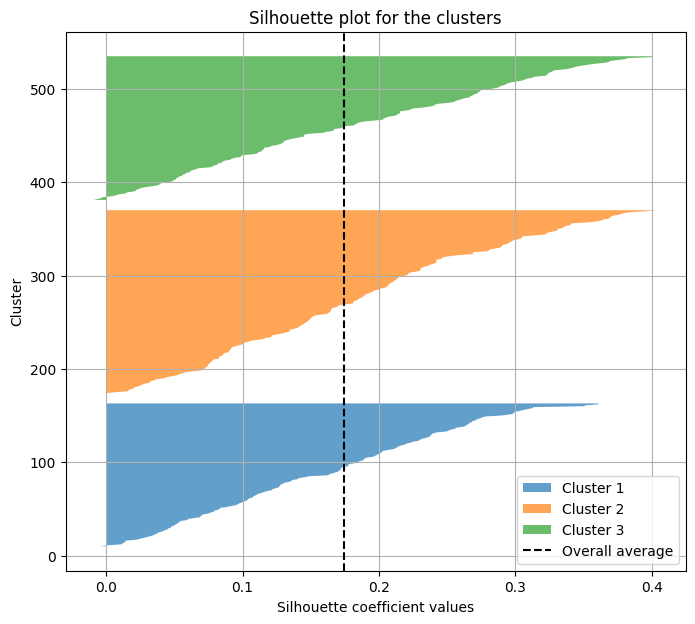

In [29]:
y_lower = 10

plt.figure(figsize=(8,7))
plt.grid()

for i in range(k):
    ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),0,
        ith_cluster_silhouette_values,
        alpha=0.7,
        label=f"Cluster {i+1}"
    )

    y_lower = y_upper + 10

# Vertical line for average silhouette score
plt.axvline(x=silhouette_avg, color="black", linestyle="--", label="Overall average")

plt.xlabel("Silhouette coefficient values")
plt.ylabel("Cluster")
plt.title("Silhouette plot for the clusters")
plt.legend()
plt.show()

The silhouette plot shows that the clustering obtained after applying k-means on the PCA-reduced data is meaningful. The overall average silhouette score is positive, indicating that individuals are generally closer to their assigned cluster than to neighboring ones.

Cluster 2 exhibits higher silhouette values and appears to be the most compact and well-separated cluster, while clusters 1 and 3 show slightly lower values, suggesting some degree of overlap and internal variability. This behavior is expected given the subjective and high-dimensional nature of survey data.

Importantly, no cluster shows a significant number of negative silhouette values, indicating the absence of strong misclassification. These results are consistent with the PCA score plots and centroid analysis previously discussed, which highlighted partially overlapping but interpretable clusters. Overall, the silhouette analysis confirms the validity of the chosen clustering configuration.